<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/24_Poisoning_Attacks_Against_QML/QSVM_ErrorPropagationPoisoning_Sultanow2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QSVM vs SVM under QUID label poisoning and Euler-angle error propagation: Sultanow et al. (2024) step by step

This notebook re-implements, runs and checks the experiments of

> Eldar Sultanow, Fation Selimllari, Siddhant Dutta, Barry D. Reese, Madjid Tehrani and William J. Buchanan,
> "Quantum error propagation", arXiv:2410.05145 [quant-ph], v2, 27 January 2025. https://arxiv.org/abs/2410.05145

The paper is part theory, part experiment. Everything in it that can be recomputed is recomputed here:

* **Part A, error propagation on the Bloch sphere (Appendices A to H).** Two single-qubit vectors that differ by a small
  Euler-angle error are rotated together, and the azimuth and elevation discrepancy is tracked (Fig. 1 / Fig. 8, the
  closed form of Eq. 9 to 11, the extrema of Tables 3 and 4, the four rational / irrational angle cases of Appendix C.4).
  The rotation is done three ways that must agree: the SU(2) matrix of Eq. 1 (Listing 8), the Euler matrix of Eq. 6
  (Listing 10) and an actual Qiskit single-qubit circuit `Rz(psi) -> Ry(theta) -> Rz(phi)` simulated as a state vector.
* **Part B, QUID label poisoning of a classical SVM and a QSVM (Sections 4 to 6, Algorithms 1 and 2, Tables 1 and 2).**
  Synthetic radar-cross-section (RCS) profiles of cylinders and cones are generated, reduced with PCA to 10 (or 31)
  features, normalised to [0, 1], and classified by a polynomial-kernel SVM and by a QSVM with a 10-qubit `ZZFeatureMap`
  fidelity kernel, before and after a QUID-style label-flip attack, over Monte Carlo runs, with the paper's paired t-test.

The theorems of Section 7 (induction over the number of qubits, Lie-algebra embedding) are proofs, not experiments, and
are not re-run. Section "Reading the paper critically" discusses what Part A does and does not say about them.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, and use *Runtime -> Run all*. The first cell installs pinned
Qiskit versions; if Colab asks to restart the session, restart and run all again. No GPU, no IBM Quantum account and no
download are needed: all data are generated inside the notebook from the paper's own formula, so no Hugging Face token is needed
either.

**Runtime.** `FAST_MODE = True` (5 Monte Carlo runs, 120 profiles each) takes about 4 minutes; the full run (30 Monte Carlo
runs of 200 profiles, as in the paper) takes about 10 to 15 minutes on a 2-core CPU. Part A takes a few seconds.

**What you get at the end.** Re-drawn Fig. 1 / Fig. 8, a corrected closed form, Tables 3 and 4 checked cell by cell, Tables 1
and 2 with mean and standard deviation over the Monte Carlo runs, the paired t-test, an extra poison-ratio sweep, and a
per-claim verdict table (reproduced / not reached / exceeded / cannot be checked).

## The paper in one page

**Question.** Does a data-poisoning error (a wrong Euler angle, or a wrong label) grow without bound as it passes through a
quantum model, as errors can in a deep classical network? Hypotheses: **H1**, the discrepancy of the Bloch-sphere angles
stays bounded; **H2**, it is periodic (rises and falls back to zero). A third hypothesis (H0 / H1 of Section 1) compares
the mean poisoned accuracy of QSVM and SVM: QSVM is "significantly more robust".

**Part A (Appendices A to H).** A qubit is the unit vector $\vec q$ on the Bloch sphere. A rotation with Euler angles
$(\varphi,\theta,\psi)$ is the SU(2) matrix $U=e^{-i\varphi\sigma_3/2}e^{-i\theta\sigma_2/2}e^{-i\psi\sigma_3/2}$ (Eq. 1), or
equivalently the $3\times3$ Euler matrix $S=S_3(\psi)S_2(\theta)S_1(\varphi)$ acting as $\vec q' = \vec q\,S$ (Eq. 6). The reference
vector is $\vec v=(1,0,0)$, the "poisoned" vector is $\vec v_{err}=\vec v\cdot S(\epsilon_x,\epsilon_y,\epsilon_z)$, and
both are rotated synchronously $t$ times. The error is the azimuth difference $\Delta_{az}$ and the elevation difference $\Delta_{el}$,
each folded as $\min(|d|,2\pi-|d|)$ (Eq. 7).

| Claim | Where |
|---|---|
| Curves for $\epsilon=(0,0.2,0)$, 200 rotations of $\pi/100$ (all three angles) are bounded and periodic | Fig. 1, Fig. 8 (Listing 8 = Listing 10) |
| Limit of infinitely many infinitesimal steps: $S_P(t)=\lim S(t/s,t/s,t/s)^s$ with period $2\pi/\sqrt5$ for equal angles, general period $T=2\pi/\sqrt{\theta^2+(\varphi+\psi)^2}$ | Eq. 9 to 11, App. B, C.1 |
| Maximum / minimum $\Delta_{el}$, $\Delta_{az}$ over $\epsilon$ and $t$ for $\vec v=(1,0,0)$: max $\Delta_{el}=2.0344424$, max $\Delta_{az}=\pi$, minima $\approx0$; for $\vec v=(0,0,1)$: both maxima $\pi$ | Table 3, Table 4 |
| Four angle-ratio cases: max $\Delta_{el}$ = 1.76818818822, 2.35590586664925 (ratios 1:2:3 and 3:2:1); 1.57079632670986, 2.35619448416057 (1:1:2 and 2:1:1); 2.07317454885058 ($\pi$, $e$, 3); 1.80771464098098, 2.57468030909556 (1:1:$\pi$ and $\pi$:1:1); periods $\sqrt{2/13}\pi$, $\sqrt2\pi/3$, $\sqrt{2/5}\pi$, $\pi/\sqrt2$, $2\pi/\sqrt{\pi^2+(e+3)^2}$, $2\pi/\sqrt{1+(\pi+1)^2}$, $2\pi/\sqrt{\pi^2+4}$ | App. C.4 |
| Time-averaged error (Eq. 12) is lower than the instantaneous maxima | App. C.3 |

**Part B (Sections 4 to 6).** Binary task: cylinder (class 1) vs cone (class 2) from synthetic RCS profiles
$\mathrm{RCS}=(rh)^2/\lambda^2\cos\theta_{az}\cos\theta_{el}$ with Gaussian noise on the angles; 701 raw features, PCA to 10, normalisation to
[0, 1]. Models: SVM with a polynomial kernel; QSVM with a `ZZFeatureMap` and `FidelityQuantumKernel` (Qiskit 1.3.1,
qiskit-machine-learning 0.8.2, ideal simulation, 10 qubits). Attack: QUID-style label poisoning (Algorithms 1 and 2): a fraction
$\epsilon$ of the training set is relabelled with the class whose clean points are on average **farthest** away (kernel-induced
distance for the SVM, distance between density matrices for the QSVM). 30 Monte Carlo runs, paired t-test on the poisoned accuracies.

| Model | Mean accuracy (%) | Std (%) |
|---|---|---|
| SVM | 50.0 | 0.0 |
| SVM (poisoned) | 49.0 | 0.0 |
| QSVM | 100.0 | 0.0 |
| QSVM (poisoned) | 100.0 | 0.0 |

Table 1 (PCA = 10). Table 2 (PCA = 31, SVM only): clean 50.0 %, poisoned 47.0 %, std 0.0. Paired t-test: T = infinity, p = 0.000.

## What follows the paper and what had to be chosen

The paper's repository (`QSVM_SVM_Poisioning.ipynb`, `rotate_su2_qiskit_eldar-sultanow.ipynb`, `errorPropagation.nb`) is not available
to this notebook; the text omits most parameters of the synthetic data and of the attack. Every choice below is marked
`# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Part A rotations, reference vector, error vector, 200 steps of $\pi/100$ | specified (Listing 8, Fig. 1) | exactly as specified |
| Euler-angle order in Tables 3 / 4 (arguments of `EulerMatrix[{x,y,z}]`) | not stated; Eq. 6 names $(\varphi,\theta,\psi)$ | tested against the tables: $(\epsilon_x,\epsilon_y,\epsilon_z)\to(\psi,\theta,\varphi)$ reproduces them (reverse of Eq. 6 reading) |
| Closed form $S_P(t)$ (Eq. 10, Listing 11) | $\exp(tJ)$ with the printed $J$ | printed form tested **and** its transpose $\exp(tJ^{\top})$, which is the true limit of $S^{n}$ |
| Synthetic RCS data: geometry ranges, wavelength, angle grid, noise level | not given (only the RCS formula, 701 features, "Gaussian noise in angles") | $\lambda=0.06$ m, 701 aspect angles 0 to 70 degrees (step 0.1), noise 2 degrees on both angles, cylinder $r\in U(0.3,0.5)$, $h\in U(2.5,3.5)$, cone $r\in U(0.3,0.5)$, $h\in U(0.5,1.5)$ |
| Samples per class, train / test split | not given | 100 per class (FAST: 60), stratified 70 / 30 split |
| Monte Carlo runs | 30 | 30 (FAST: 5), data regenerated per run with seed `SEED + run` |
| PCA and normalisation | PCA to 10 (31), then [0, 1] | PCA and `MinMaxScaler` fitted on the training split only, test clipped to [0, 1] |
| SVM | "polynomial kernel" | `SVC(kernel="poly")`, scikit-learn defaults (degree 3, `gamma="scale"`, `C=1`) |
| QSVM | `ZZFeatureMap` + `FidelityQuantumKernel` | `zz_feature_map(10, reps=2, entanglement="full")` (Qiskit defaults), exact statevector fidelities, `SVC(kernel="precomputed", C=1)`; checked against `QSVC` + `FidelityStatevectorKernel` and `FidelityQuantumKernel` |
| Poison ratio $\epsilon$ | symbol only | 0.2 for the main tables, sweep 0 to 0.5 as an extra |
| Poison set selection | "split $D_{tr}$ into $D_c$ and $D_p$ with ratio $\epsilon$" | random subset of the training set, same indices for SVM and QSVM in a run |
| Distance | kernel-induced (SVM), "distance for density matrices" (QSVM) | $d=\sqrt{k(x,x)+k(x',x')-2k(x,x')}$ (SVM); trace distance of pure states $\sqrt{1-F}$ (QSVM) |
| t-test | paired, $p<0.05$ | `scipy.stats.ttest_rel(..., alternative="greater")`, plus a Wilcoxon signed-rank test |
| Classical baselines on identical inputs | SVM (poly) only | SVM (poly), SVM (RBF), RandomForest on the same normalised PCA features |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, scipy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever qiskit-machine-learning is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-machine-learning already present; skipping pip install.")

qiskit-machine-learning already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
import numpy as np
FAST_MODE = False          # True: class demo in about 4 minutes. False: the paper's 30 Monte Carlo runs (about 10-15 min on CPU).
SEED      = 42             # CHOICE: the paper gives no seed
DATA_DIR  = "data"         # not used for downloads: the paper's data are synthetic and generated below
IBM_TOKEN = ""             # optional; not needed (ideal simulation, as in the paper)

# ---- Part A: single-qubit error propagation (paper, Listing 8 / Fig. 1) ----
N_STEPS   = 200            # paper: 200 consecutive rotations
STEP      = np.pi / 100  # paper: rotation by pi/100 in each Euler angle
EPS_ERR   = (0.0, 0.2, 0.0)  # paper: (eps_x, eps_y, eps_z) = (0, 0.2, 0)

# ---- Part B: synthetic RCS data, QUID poisoning, QSVM vs SVM (paper Sections 4 to 6) ----
N_RUNS        = 5 if FAST_MODE else 30       # paper: 30 Monte Carlo runs
N_PER_CLASS   = 60 if FAST_MODE else 100     # CHOICE: samples per class (paper: not given)
TEST_SIZE     = 0.3                          # CHOICE
N_ANGLES      = 701                          # paper: 701 raw features
AZ_RANGE_DEG  = (0.0, 70.0)                  # CHOICE: aspect-angle sweep, 701 points = 0.1 degree steps
ANGLE_NOISE_DEG = 2.0                        # CHOICE: std of the Gaussian noise on azimuth and elevation
EL0_MAX_DEG   = 10.0                         # CHOICE: random mean elevation in +-10 degrees
WAVELENGTH    = 0.06                         # CHOICE: lambda in metres (5 GHz)
GEOMETRY = {                                 # CHOICE: (radius range, height range) in metres
    "cylinder": ((0.3, 0.5), (2.5, 3.5)),
    "cone":     ((0.3, 0.5), (0.5, 1.5)),
}
N_PCA, N_PCA_HIGH = 10, 31                   # paper: Table 1 (PCA = 10), Table 2 (PCA = 31, SVM only)
FM_REPS, FM_ENTANGLEMENT = 2, "full"         # CHOICE: Qiskit's ZZFeatureMap defaults
POISON_RATIO  = 0.2                          # CHOICE: epsilon of Algorithms 1 and 2 (paper: symbol only)
EPS_SWEEP     = [0.0, 0.2, 0.4] if FAST_MODE else [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]   # extra: poison-ratio sweep
CLASS_NAMES   = {0: "cylinder", 1: "cone"}
print("FAST_MODE =", FAST_MODE, "| N_RUNS =", N_RUNS, "| samples per run =", 2 * N_PER_CLASS)

FAST_MODE = False | N_RUNS = 30 | samples per run = 200


In [3]:
import os, time, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy import stats, optimize

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import polynomial_kernel, rbf_kernel

import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector, Operator, Pauli
from qiskit_machine_learning.kernels import FidelityStatevectorKernel, FidelityQuantumKernel
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.utils import algorithm_globals

pi = np.pi
algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 80); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__)
print("numpy", np.__version__, "| scipy", __import__("scipy").__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1
numpy 2.5.4 | scipy 1.18.1 | scikit-learn 1.9.1 | pandas 3.0.6


## 1. Part A: rotating a qubit and its error vector (Appendices A and B)

**The qubit as a vector.** A pure qubit state has a Bloch vector $\vec q=(\sin\theta_{el}\cos\varphi_{az},\ \sin\theta_{el}\sin\varphi_{az},\ \cos\theta_{el})$
(Eq. 2). Here $\theta_{el}\in[0,\pi]$ is measured **from the +z axis** (the paper calls it "elevation" but the code, `np.arctan2(hxy, z)`, makes it
the polar angle) and $\varphi_{az}\in(-\pi,\pi]$ is the azimuth.

**Two equivalent rotations.** The SU(2) matrix of Eq. 1 acts as $M_q'=U M_q U^\dagger$ with $M_q=\vec q\cdot\vec\sigma$ (Listing 4), and the Euler matrix of Eq. 6
acts as $\vec q'=\vec q\,S$. The cell below implements both, with the paper's function names, and checks numerically that they are the same rotation: the Euler
matrix $S(\varphi,\theta,\psi)$ is the transpose of the active rotation $R_z(\varphi)R_y(\theta)R_z(\psi)$ that $U$ induces on Bloch vectors, so a row vector times $S$
is the Bloch vector after the gate sequence $R_z(\psi)$, then $R_y(\theta)$, then $R_z(\varphi)$.

**The error.** $\vec v_{err}=\vec v\,S(\epsilon_x,\epsilon_y,\epsilon_z)$ is the "poisoned" copy of $\vec v$. After each synchronous rotation the azimuth and
elevation differences $\Delta_{az},\Delta_{el}$ are recorded (Eq. 7), each folded as $\min(|d|,2\pi-|d|)$.

In [4]:
# ---- the paper's building blocks (Listings 2-4, Eq. 1, 3, 6, 7) in plain numpy ----
SIGMA = [np.array([[0, 1], [1, 0]], complex), np.array([[0, -1j], [1j, 0]]), np.array([[1, 0], [0, -1]], complex)]

def cartesian_to_spherical(vec):                    # Listing 2: returns [r, theta_el (polar), phi_az]
    x, y, z = (float(np.real(c)) for c in vec)
    hxy = np.hypot(x, y)
    return [np.hypot(hxy, z), np.arctan2(hxy, z), np.arctan2(y, x)]

def qubitmatrix_to_cartesian(Mq):                   # Listing 3 / Eq. 13
    return np.array([np.real((Mq[0, 1] + Mq[1, 0]) / 2), np.real((Mq[1, 0] - Mq[0, 1]) / 2j), np.real(Mq[0, 0])])

def U_su2(phi, theta, psi):                         # Eq. 1 written out
    return np.array([[np.exp(-1j * (phi + psi) / 2) * np.cos(theta / 2), -np.exp(-1j * (phi - psi) / 2) * np.sin(theta / 2)],
                     [np.exp(1j * (phi - psi) / 2) * np.sin(theta / 2),   np.exp(1j * (phi + psi) / 2) * np.cos(theta / 2)]])

def rn_su2_euler(vec, rx, ry, rz):                  # Listing 4: M' = U M U^dagger, (phi, theta, psi) = (rx, ry, rz)
    _, th, ph = cartesian_to_spherical(vec)
    Mq = np.sin(th) * np.cos(ph) * SIGMA[0] + np.sin(th) * np.sin(ph) * SIGMA[1] + np.cos(th) * SIGMA[2]
    U = U_su2(rx, ry, rz)
    return U @ Mq @ U.conj().T

def S_euler(phi, theta, psi):                       # Eq. 6: S = S3(psi) S2(theta) S1(phi), used as  q' = q @ S
    c, s = np.cos, np.sin
    S3 = np.array([[c(psi), s(psi), 0], [-s(psi), c(psi), 0], [0, 0, 1]])
    S2 = np.array([[c(theta), 0, -s(theta)], [0, 1, 0], [s(theta), 0, c(theta)]])
    S1 = np.array([[c(phi), s(phi), 0], [-s(phi), c(phi), 0], [0, 0, 1]])
    return S3 @ S2 @ S1

def fold(a, b):                                     # Eq. 7: min(|a-b|, 2pi-|a-b|)
    d = abs(a - b)
    return min(d, 2 * pi - d)

def angular_errors(w, w_err):                       # (Delta_az, Delta_el) of two Cartesian vectors
    _, th1, ph1 = cartesian_to_spherical(w); _, th2, ph2 = cartesian_to_spherical(w_err)
    return fold(ph2, ph1), fold(th2, th1)

# ---- consistency checks between the two representations ----
r = np.random.default_rng(SEED)
for _ in range(5):
    a, b, c = r.uniform(0, 2 * pi, 3)
    v = r.normal(size=3); v /= np.linalg.norm(v)
    v_su2 = qubitmatrix_to_cartesian(rn_su2_euler(v, a, b, c))
    assert np.allclose(v_su2, v @ S_euler(a, b, c)), "SU(2) rotation and Euler matrix disagree"
    assert abs(np.linalg.det(S_euler(a, b, c)) - 1) < 1e-12 and np.allclose(S_euler(a, b, c) @ S_euler(a, b, c).T, np.eye(3))
print("Eq. 1 (SU(2), Listing 4) and Eq. 6 (Euler matrix) give the same rotated vector in 5 random tests; S is orthogonal with det 1.")
v0 = np.array([1.0, 0, 0]); v_err0 = v0 @ S_euler(*EPS_ERR)
print("v_err =", np.round(v_err0, 8), "  (paper footnote: (0.98, 0, -0.19866933))")

Eq. 1 (SU(2), Listing 4) and Eq. 6 (Euler matrix) give the same rotated vector in 5 random tests; S is orthogonal with det 1.
v_err = [ 0.98006658  0.         -0.19866933]   (paper footnote: (0.98, 0, -0.19866933))


### 1.1 Fig. 1 and Fig. 8: 200 synchronous rotations by $\pi/100$

Listing 8 does the loop with SU(2) matrices, Listing 10 does it with powers of the Euler matrix. Both are run; they must give the same curves, and the
curves must look like Fig. 1: $\Delta_{el}$ starts at 0.2 (the initial error is a pure elevation tilt of 0.2 rad) and the vertical axis of the paper's figure runs up to 0.20.

max |SU(2) curve - Euler curve| over t = 0..199 : 1.5543122344752192e-15
Delta_az : min 0.0000  max 0.1629  (t = 128)
Delta_el : min 0.1192  max 0.2000  (t = 0)   -> paper's Fig. 1 axis spans 0.05 to 0.20


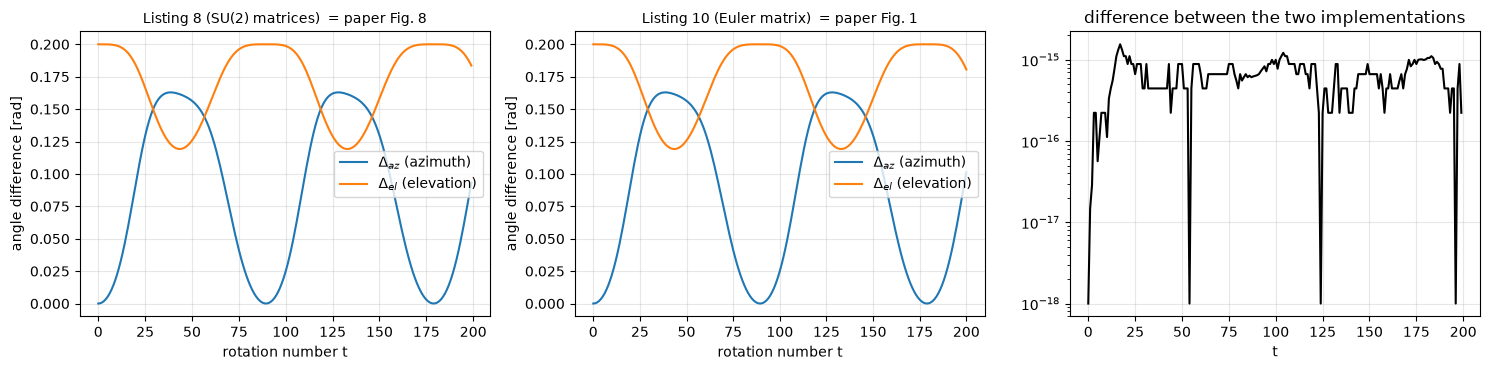

In [5]:
def error_curve_su2(n=N_STEPS, step=STEP, eps=EPS_ERR):
    """Listing 8: rotate v and v_err with SU(2), record (Delta_az, Delta_el) BEFORE each rotation (n points, t = 0..n-1)."""
    vec = np.array([1.0, 0, 0]); vec_err = qubitmatrix_to_cartesian(rn_su2_euler(vec, 0, eps[1], 0))   # paper: rotation by (0, err, 0)
    out = np.zeros((n, 2))
    for i in range(n):
        out[i] = angular_errors(vec, vec_err)
        vec = qubitmatrix_to_cartesian(rn_su2_euler(vec, step, step, step))
        vec_err = qubitmatrix_to_cartesian(rn_su2_euler(vec_err, step, step, step))
    return out

def error_curve_euler(n=N_STEPS, step=STEP, eps=EPS_ERR, t0=0):
    """Listing 10: v . S^t and v_err . S^t for t = 0..n (n+1 points)."""
    S = S_euler(step, step, step); v = np.array([1.0, 0, 0]); ve = v @ S_euler(*eps)
    out = np.zeros((n + 1, 2))
    for t in range(n + 1):
        out[t] = angular_errors(v, ve); v = v @ S; ve = ve @ S
    return out

c_su2, c_eul = error_curve_su2(), error_curve_euler()
print("max |SU(2) curve - Euler curve| over t = 0..199 :", np.abs(c_su2 - c_eul[:N_STEPS]).max())
print(f"Delta_az : min {c_eul[:,0].min():.4f}  max {c_eul[:,0].max():.4f}  (t = {c_eul[:,0].argmax()})")
print(f"Delta_el : min {c_eul[:,1].min():.4f}  max {c_eul[:,1].max():.4f}  (t = {c_eul[:,1].argmax()})   -> paper's Fig. 1 axis spans 0.05 to 0.20")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c, ttl in [(axes[0], c_su2, "Listing 8 (SU(2) matrices)  = paper Fig. 8"), (axes[1], c_eul, "Listing 10 (Euler matrix)  = paper Fig. 1")]:
    ax.plot(c[:, 0], label=r"$\Delta_{az}$ (azimuth)", color="tab:blue"); ax.plot(c[:, 1], label=r"$\Delta_{el}$ (elevation)", color="tab:orange")
    ax.set_title(ttl, fontsize=10); ax.set_xlabel("rotation number t"); ax.set_ylabel("angle difference [rad]"); ax.legend()
axes[2].semilogy(np.abs(c_su2 - c_eul[:N_STEPS]).max(1) + 1e-18, color="k"); axes[2].set_title("difference between the two implementations")
axes[2].set_xlabel("t"); plt.tight_layout(); plt.show()

### 1.2 The same experiment as a Qiskit circuit

The paper's setting is quantum machine learning, so the rotation is also executed as a gate sequence. The SU(2) element of Eq. 1 is
$U(\varphi,\theta,\psi)=R_z(\varphi)R_y(\theta)R_z(\psi)$ with Qiskit's $R_z(\lambda)=e^{-i\lambda Z/2}$ and $R_y(\lambda)=e^{-i\lambda Y/2}$, i.e. the circuit applies
`rz(psi)`, then `ry(theta)`, then `rz(phi)`. The cell checks that the circuit unitary equals the explicit matrix of Eq. 1 element by element, prepares the
state with Bloch vector $(1,0,0)$ ($|+\rangle$) and the "poisoned" state $R_y(0.2)|+\rangle$, applies the circuit 200 times to both state vectors, and compares the Bloch
vectors with the Euler-matrix trajectory. It also tracks two quantities the paper does not plot: the **fidelity** $|\langle\psi|\psi_{err}\rangle|^2$ and the **Euclidean distance** of the two Bloch vectors.

Operator(circuit) == Eq. 1 matrix: OK
Bloch(|+>) = [1. 0. 0.] | Bloch(v_err) = [ 0.98006658  0.         -0.19866933] | numpy v_err = [ 0.98006658  0.         -0.19866933]


max |Qiskit curve - Euler curve| = 3.3306690738754696e-15  (should be ~1e-12)
fidelity |<psi|psi_err>|^2 : min 0.990033288921  max 0.990033288921   (cos^2(0.1) = 0.990033288921)
Euclidean Bloch distance   : min 0.199666833294  max 0.199666833294   (2 sin(0.1) = 0.199666833294)


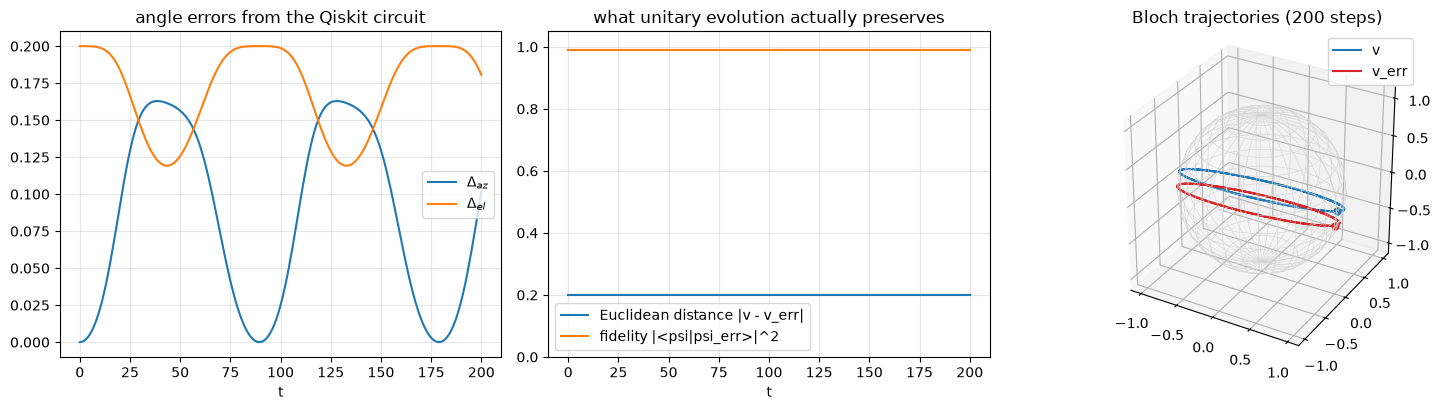

In [6]:
def u_circuit(phi, theta, psi):
    """Single-qubit circuit for U(phi, theta, psi) = Rz(phi) Ry(theta) Rz(psi): gates in time order rz(psi), ry(theta), rz(phi)."""
    qc = QuantumCircuit(1, name="U(phi,theta,psi)")
    qc.rz(psi, 0); qc.ry(theta, 0); qc.rz(phi, 0)
    return qc

def bloch(sv):
    return np.array([sv.expectation_value(Pauli(p)).real for p in "XYZ"])

# 1) the circuit IS the matrix of Eq. 1 (exactly, including the global phase)
rg = np.random.default_rng(SEED)
for _ in range(5):
    a, b, c = rg.uniform(0, 2 * pi, 3)
    assert np.allclose(Operator(u_circuit(a, b, c)).data, U_su2(a, b, c)), "circuit != Eq. 1"
print("Operator(circuit) == Eq. 1 matrix: OK")

# 2) states: v = |+> (Bloch (1,0,0)), v_err = Ry(0.2)|+>
U_STEP = u_circuit(STEP, STEP, STEP)
sv  = Statevector.from_label("+")
sv_err = sv.evolve(QuantumCircuit(1).compose(u_circuit(0, EPS_ERR[1], 0)))        # theta = 0.2, phi = psi = 0
print("Bloch(|+>) =", np.round(bloch(sv), 6), "| Bloch(v_err) =", np.round(bloch(sv_err), 8), "| numpy v_err =", np.round(v_err0, 8))

traj, traj_err, fid, dist = [], [], [], []
for t in range(N_STEPS + 1):
    traj.append(bloch(sv)); traj_err.append(bloch(sv_err))
    fid.append(abs(sv.inner(sv_err)) ** 2); dist.append(np.linalg.norm(traj[-1] - traj_err[-1]))
    sv, sv_err = sv.evolve(U_STEP), sv_err.evolve(U_STEP)
traj, traj_err, fid, dist = map(np.array, (traj, traj_err, fid, dist))
c_qc = np.array([angular_errors(a, b) for a, b in zip(traj, traj_err)])
print("max |Qiskit curve - Euler curve| =", np.abs(c_qc - c_eul).max(), " (should be ~1e-12)")
print(f"fidelity |<psi|psi_err>|^2 : min {fid.min():.12f}  max {fid.max():.12f}   (cos^2(0.1) = {np.cos(0.1)**2:.12f})")
print(f"Euclidean Bloch distance   : min {dist.min():.12f}  max {dist.max():.12f}   (2 sin(0.1) = {2*np.sin(0.1):.12f})")

fig = plt.figure(figsize=(15, 4.2))
ax = fig.add_subplot(1, 3, 1); ax.plot(c_qc[:, 0], label=r"$\Delta_{az}$"); ax.plot(c_qc[:, 1], label=r"$\Delta_{el}$")
ax.set_title("angle errors from the Qiskit circuit"); ax.set_xlabel("t"); ax.legend()
ax = fig.add_subplot(1, 3, 2); ax.plot(dist, label="Euclidean distance |v - v_err|"); ax.plot(fid, label="fidelity |<psi|psi_err>|^2")
ax.set_ylim(0, 1.05); ax.set_title("what unitary evolution actually preserves"); ax.set_xlabel("t"); ax.legend()
ax = fig.add_subplot(1, 3, 3, projection="3d")
u_, v_ = np.mgrid[0:2 * pi:30j, 0:pi:15j]
ax.plot_wireframe(np.cos(u_) * np.sin(v_), np.sin(u_) * np.sin(v_), np.cos(v_), color="lightgray", linewidth=0.4)
ax.plot(*traj.T, color="tab:blue", label="v"); ax.plot(*traj_err.T, color="tab:red", label="v_err")
ax.scatter(*traj[0], color="tab:blue", s=25); ax.scatter(*traj_err[0], color="tab:red", s=25)
ax.set_title("Bloch trajectories (200 steps)"); ax.legend(); ax.set_box_aspect((1, 1, 1))
plt.tight_layout(); plt.show()

### 1.3 Closed form for infinitely many infinitesimal steps (Eq. 9 and 10, Listing 11)

The paper replaces the 200 discrete steps by the limit $S_P(t)=\lim_{s\to\infty}S(\varphi t/s,\theta t/s,\psi t/s)^s=\exp(tJ)$ with the generator
$J=\begin{pmatrix}0&-(\varphi+\psi)&\theta\\ \varphi+\psi&0&0\\ -\theta&0&0\end{pmatrix}$ (for equal angles $\varphi=\theta=\psi=1$: $J$ has eigenvalues $0,\pm i\sqrt5$, hence the period $2\pi/\sqrt5$).
Listing 11 then applies this $S_P(t)$ to the row vectors $\vec v$ and $\vec v_{err}$ and claims to "generate exactly the same blue and orange curve" as Fig. 1.

Two readings are tested against the discrete rotation $S^k$ (with $k$ steps of $2\pi/200$ corresponding to $t=2\pi k/200$): the **printed** $\exp(tJ)$ and its **transpose**
$\exp(tJ^{\top})$. Since $S\approx I+J^{\top}$ to first order, the true limit of $S^n$ is $\exp(tJ^{\top})$; the printed form is the inverse rotation, i.e. time-reversed.

angles (1, 1, 1): |S(t/s)^s - exp(tJ^T)| = 1.22e-11   |S(t/s)^s - exp(tJ)| = 1.10e+00
angles (0.7, 1.3, 2.1): |S(t/s)^s - exp(tJ^T)| = 2.15e-06   |S(t/s)^s - exp(tJ)| = 1.56e+00
eigenvalues of J (equal angles): [0.+2.236068j 0.-2.236068j 0.+0.j      ]  sqrt(5) = 2.236068
max |closed form - discrete rotation| (Delta_az, Delta_el):
   printed exp(tJ)   : [0.02006 0.00734]
   transposed exp(tJ^T): [6.e-05 4.e-05]   (residual = finite step size, shrinks as 1/s)


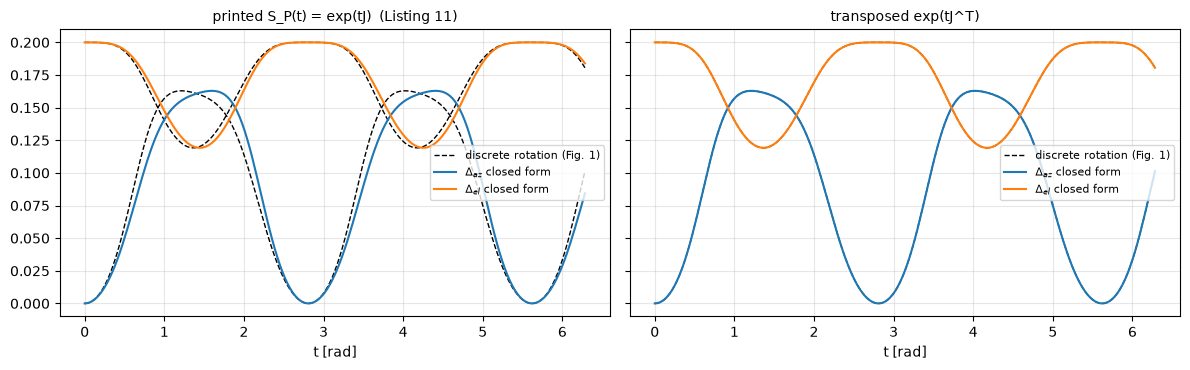

periodicity: max |Delta(eps, t) - Delta(eps, t + 2pi/sqrt5)| over 200 random (eps, t) = 1.54e-13


In [7]:
def J_general(phi, theta, psi):
    a = phi + psi
    return np.array([[0, -a, theta], [a, 0, 0], [-theta, 0, 0]], float)

def SP_literal(t, phi=1, theta=1, psi=1):   return expm(t * J_general(phi, theta, psi))      # the paper's printed S_P(t) = exp(tJ)
def SP_corrected(t, phi=1, theta=1, psi=1): return expm(t * J_general(phi, theta, psi).T)    # true limit of S(t/s)^s for row vectors

# 1) the limit itself (Eq. 9): S(t/s)^s -> exp(t J^T)
for (p, th, ps) in [(1, 1, 1), (0.7, 1.3, 2.1)]:
    t, s_big = 1.7, 200_000
    lim = np.linalg.matrix_power(S_euler(p * t / s_big, th * t / s_big, ps * t / s_big), s_big)
    print(f"angles {(p, th, ps)}: |S(t/s)^s - exp(tJ^T)| = {np.abs(lim - SP_corrected(t, p, th, ps)).max():.2e}   |S(t/s)^s - exp(tJ)| = {np.abs(lim - SP_literal(t, p, th, ps)).max():.2e}")
print("eigenvalues of J (equal angles):", np.round(np.linalg.eigvals(J_general(1, 1, 1)), 6), " sqrt(5) =", round(np.sqrt(5), 6))

# 2) Fig. 1 curves from the closed forms vs the discrete rotation (t = 2 pi k / 200)
def curve_closed(SPfun, ts, eps=EPS_ERR, vec=(1.0, 0, 0), **kw):
    v = np.array(vec, float); ve = v @ S_euler(*eps)
    return np.array([angular_errors(v @ SPfun(t, **kw), ve @ SPfun(t, **kw)) for t in ts])

ts = 2 * pi * np.arange(N_STEPS + 1) / 200
cl_lit, cl_cor = curve_closed(SP_literal, ts), curve_closed(SP_corrected, ts)
print("max |closed form - discrete rotation| (Delta_az, Delta_el):")
print("   printed exp(tJ)   :", np.round(np.abs(cl_lit - c_eul).max(0), 5))
print("   transposed exp(tJ^T):", np.round(np.abs(cl_cor - c_eul).max(0), 5), "  (residual = finite step size, shrinks as 1/s)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, cl, ttl in [(axes[0], cl_lit, "printed S_P(t) = exp(tJ)  (Listing 11)"), (axes[1], cl_cor, "transposed exp(tJ^T)")]:
    ax.plot(ts, c_eul[:, 0], "k--", lw=1, label="discrete rotation (Fig. 1)"); ax.plot(ts, c_eul[:, 1], "k--", lw=1)
    ax.plot(ts, cl[:, 0], color="tab:blue", label=r"$\Delta_{az}$ closed form"); ax.plot(ts, cl[:, 1], color="tab:orange", label=r"$\Delta_{el}$ closed form")
    ax.set_title(ttl, fontsize=10); ax.set_xlabel("t [rad]"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# 3) period 2 pi / sqrt(5) for ANY error vector (App. C.1)
T5 = 2 * pi / np.sqrt(5); r = np.random.default_rng(SEED)
worst = 0.0
for _ in range(200):
    eps = r.uniform(0, 2 * pi, 3); t = r.uniform(0, 2 * pi)
    a = curve_closed(SP_corrected, [t], eps); b = curve_closed(SP_corrected, [t + T5], eps)
    worst = max(worst, np.abs(a - b).max())
print(f"periodicity: max |Delta(eps, t) - Delta(eps, t + 2pi/sqrt5)| over 200 random (eps, t) = {worst:.2e}")

### 1.4 Tables 3 and 4: extrema of $\Delta_{el}$ and $\Delta_{az}$

Appendix C.2 lists, for $\vec v=(1,0,0)$ (Table 3) and $\vec v=(0,0,1)$ (Table 4), the values of $(\epsilon_x,\epsilon_y,\epsilon_z)$ and $t$ at which a numerical search (`NMaximize`) found the extreme discrepancies.
Each of the eight rows is re-evaluated here under the four readings that matter: the Euler-angle order (Eq. 6 read literally, $(\epsilon_x,\epsilon_y,\epsilon_z)\to(\varphi,\theta,\psi)$, versus the
reverse order that Mathematica's `EulerMatrix[{x, y, z}]` implies) and the printed or transposed $S_P$. A row is "matched" when the value agrees with the paper to $10^{-4}$ (maxima) or is below $10^{-2}$ (minima, "$\approx 0$").
Then the maxima are verified independently: analytically (orbit geometry) and by a global optimiser over $(\epsilon_x,\epsilon_y,\epsilon_z,t)$.

In [8]:
def delta_at(vec, eps, t, SPfun, order):
    """Delta_az, Delta_el of vec.SP(t) vs (vec.S(eps)).SP(t).  order='eq6': (eps)->(phi,theta,psi); 'rev': (eps_x,eps_y,eps_z)->(psi,theta,phi)."""
    a, b, c = eps
    S = S_euler(a, b, c) if order == "eq6" else S_euler(c, b, a)
    v = np.array(vec, float); M = SPfun(t)
    return angular_errors(v @ M, (v @ S) @ M)

TABLE3 = [  # label, vector, (eps_x, eps_y, eps_z), t, paper value, which angle
    ("T3 max Delta_el", (1, 0, 0), (5.77302981892348, 4.3028173057175945, 4.602388461805818), 3.511308418550631, 2.0344424161175363, "el"),
    ("T3 max Delta_az", (1, 0, 0), (1.697427669696458, 6.202505314481809, 1.4563517625363593), 3.952403209518636, pi, "az"),
    ("T3 min Delta_el", (1, 0, 0), (1.6952986881010703, 1.546558501896838, 4.608182273912689), 4.061805642653761, 0.0, "el"),
    ("T3 min Delta_az", (1, 0, 0), (5.017163536971859, 3.9579710903948024, 1.7852930269424405), 2.911162125823624, 0.0, "az"),
    ("T4 max Delta_el", (0, 0, 1), (3.373959984091561, pi, 2.8479974737420557), 2 * pi / np.sqrt(5), pi, "el"),
    ("T4 max Delta_az", (0, 0, 1), (3.117350980755296, pi, 4.292091776219165), 4.555204697315162, pi, "az"),
    ("T4 min Delta_el", (0, 0, 1), (5.651168952220518, 6.283102504046935, 0.8902613576650594), 6.277761692229545, 0.0, "el"),
    ("T4 min Delta_az", (0, 0, 1), (1.626524700226482, 2 * pi, 0.18398822116968577), 6.252198460931593, 0.0, "az"),
]
variants = [("Eq.6 order, printed SP", "eq6", SP_literal), ("Eq.6 order, transposed SP", "eq6", SP_corrected),
            ("reverse order, printed SP", "rev", SP_literal), ("reverse order, transposed SP", "rev", SP_corrected)]
rows = []
for label, vec, eps, t, paper, which in TABLE3:
    row = {"row": label, "paper": round(paper, 6)}
    for name, order, SPf in variants:
        val = delta_at(vec, eps, t, SPf, order)[0 if which == "az" else 1]
        ok = abs(val - paper) < (1e-4 if paper > 0.5 else 1e-2)
        row[name] = f"{val:.5f}" + (" *" if ok else "")
    rows.append(row)
tab34 = pd.DataFrame(rows)
display(tab34)
print("* = matches the paper's value (1e-4 for maxima, < 1e-2 for 'about 0').  Reading the columns: a variant is supported if it has * in all eight rows.")

,row,paper,"Eq.6 order, printed SP","Eq.6 order, transposed SP","reverse order, printed SP","reverse order, transposed SP"
0,T3 max Delta_el,2.034442,1.15195,0.22619,0.17986,2.03444 *
1,T3 max Delta_az,3.141593,3.12592,3.12595,3.14159 *,3.14159 *
2,T3 min Delta_el,0.000000,0.16008,0.16009,0.00389 *,0.00000 *
3,T3 min Delta_az,0.000000,0.15660,0.16156,0.00000 *,0.00000 *
4,T4 max Delta_el,3.141593,3.14159 *,3.14159 *,3.14159 *,3.14159 *
5,T4 max Delta_az,3.141593,3.14159 *,3.14159 *,3.14159 *,3.14159 *
6,T4 min Delta_el,0.000000,0.00002 *,0.00008 *,0.00008 *,0.00000 *
7,T4 min Delta_az,0.000000,0.00000 *,0.00000 *,0.00000 *,0.00000 *


* = matches the paper's value (1e-4 for maxima, < 1e-2 for 'about 0').  Reading the columns: a variant is supported if it has * in all eight rows.


In [9]:
# ---- independent verification of the extrema ----
def max_delta_el_orbit(vec, SPfun, T, n_t=20001):
    """v_err ranges over the whole sphere (every point is v.S(eps) for some eps), so for each t the best v_err puts its polar angle at 0 or pi.
    Maximum Delta_el over (eps, t) = max over t of max(theta_w, pi - theta_w), where w = v.SP(t)."""
    th = np.array([cartesian_to_spherical(np.array(vec, float) @ SPfun(t))[1] for t in np.linspace(0, T, n_t)])
    return max(th.max(), (pi - th).max()), th.min(), th.max()

mx, thmin, thmax = max_delta_el_orbit((1, 0, 0), SP_corrected, T5)
n_z = 2 / np.sqrt(5)                                   # z-component of the rotation axis (0, 1, 2)/sqrt(5)
closed = pi - np.arccos(np.sqrt(1 - n_z ** 2))
print(f"v = (1,0,0): polar angle of w = v.S_P(t) sweeps [{thmin:.6f}, {thmax:.6f}] rad;  analytic bound pi - arccos(sqrt(1 - n_z^2)) = {closed:.10f}")
print(f"             max Delta_el over (eps, t) from the orbit = {mx:.10f}   | paper (Table 3, numerical NMaximize) = 2.0344424161175363")

# global optimiser over (eps_x, eps_y, eps_z, t), the paper's own approach (reverse order, transposed SP)
def neg_el(p, vec, which):
    d = delta_at(vec, p[:3], p[3], SP_corrected, "rev")
    return -d[1 if which == "el" else 0]
de_res = {}
for vec in [(1, 0, 0), (0, 0, 1)]:
    for which in ["el", "az"]:
        res = optimize.differential_evolution(neg_el, [(0, 2 * pi)] * 3 + [(0, 2 * pi)], args=(vec, which), seed=SEED, maxiter=150, popsize=30, tol=1e-12, polish=True)
        de_res[(vec, which)] = -res.fun
        print(f"global search, v = {vec}, max Delta_{which}: {-res.fun:.8f}   (paper: {'2.03444242' if (vec, which) == ((1,0,0), 'el') else '3.14159265'})")

v = (1,0,0): polar angle of w = v.S_P(t) sweeps [1.107149, 2.034444] rad;  analytic bound pi - arccos(sqrt(1 - n_z^2)) = 2.0344439358
             max Delta_el over (eps, t) from the orbit = 2.0344439358   | paper (Table 3, numerical NMaximize) = 2.0344424161175363


global search, v = (1, 0, 0), max Delta_el: 2.03444393   (paper: 2.03444242)


global search, v = (1, 0, 0), max Delta_az: 3.14159265   (paper: 3.14159265)


global search, v = (0, 0, 1), max Delta_el: 3.14159265   (paper: 3.14159265)


global search, v = (0, 0, 1), max Delta_az: 3.14159265   (paper: 3.14159265)


### 1.5 Appendix C.4: four families of angle ratios

For general angles the generator $J$ has rotation axis $\propto(0,\theta,\varphi+\psi)$ and angular speed $\omega=\sqrt{\theta^2+(\varphi+\psi)^2}$, so the period is $T=2\pi/\omega$ and, because $\vec v=(1,0,0)$ is
orthogonal to that axis, the orbit of $\vec v$ is a great circle whose largest $|z|$ is $\sqrt{1-n_z^2}$ with $n_z=(\varphi+\psi)/\omega$. The maximum elevation difference is therefore $\pi-\arccos\sqrt{1-n_z^2}$.

The text labels the ratio lists "corresponding to $\psi,\theta,\varphi$", but the periods and maxima it prints only fit if the **first listed number is $\theta$** (the middle rotation) and the other two are $\varphi,\psi$. Both readings are computed.

,case,paper max El,ours max El (theta=first),"ours max El (psi,theta,phi)=list",paper period,T (theta=first),"T (psi,theta,phi)=list",periodic check
0,C1.1 1:2:3,1.768188,1.768192,2.034444,1.232234,1.232234,1.404963,2e-13
1,C1.2 3:2:1,2.355906,2.356194,2.034444,1.480961,1.480961,1.404963,1e-13
2,C2.1 1:1:2,1.570796,1.892547,1.892547,1.986918,1.986918,1.986918,8e-14
3,C2.2 2:1:1,2.356194,2.356194,1.892547,2.221441,2.221441,1.986918,2e-13
4,"C3 pi, e, 3",2.073175,2.073175,1.987481,0.963023,0.963023,0.935518,2e-13
5,C4.1 1:1:pi,1.807715,1.807715,1.807715,1.474715,1.474715,1.474715,1e-13
6,C4.2 pi:1:1,2.574680,2.574681,1.807715,1.687127,1.687127,1.474715,2e-13


periods matching the paper : 7/7 with 'first listed = theta', 2/7 with the text's labelling (psi, theta, phi)
maxima  matching the paper : 6/7 with 'first listed = theta', 1/7 with the text's labelling
cases whose printed maximum differs from the true maximum: ['C2.1  1:1:2']


C2.1  1:1:2: paper max Delta_el = 1.570796 (pi/2); a global search over (eps, t) finds 1.892545 at eps = [3.59  4.668 5.377], t = 1.491; analytic maximum 1.892547


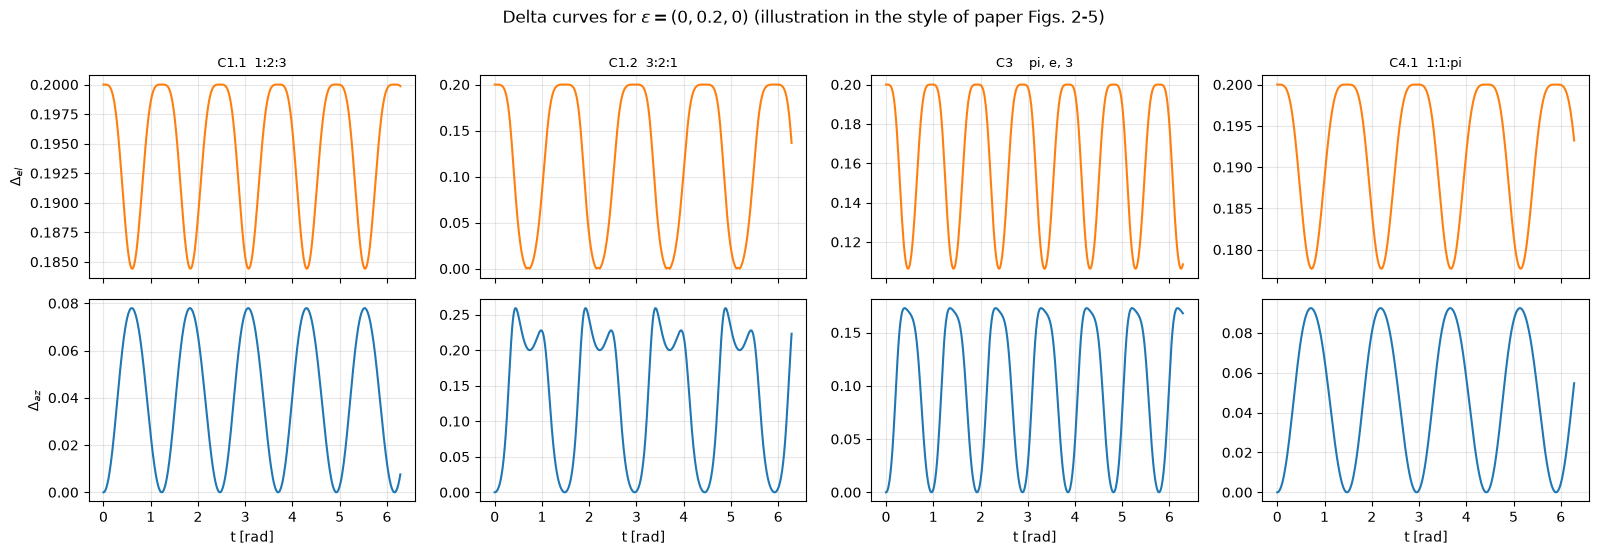

In [10]:
CASES = [  # name, (a, b, c), paper max Delta_el, paper period
    ("C1.1  1:2:3",      (1, 2, 3),      1.76818818822050, np.sqrt(2 / 13) * pi),
    ("C1.2  3:2:1",      (3, 2, 1),      2.35590586664925, np.sqrt(2) * pi / 3),
    ("C2.1  1:1:2",      (1, 1, 2),      1.57079632670986, np.sqrt(2 / 5) * pi),
    ("C2.2  2:1:1",      (2, 1, 1),      2.35619448416057, pi / np.sqrt(2)),
    ("C3    pi, e, 3",   (pi, np.e, 3),  2.07317454885058, 2 * pi / np.sqrt(pi ** 2 + (np.e + 3) ** 2)),
    ("C4.1  1:1:pi",     (1, 1, pi),     1.80771464098098, 2 * pi / np.sqrt(1 + (pi + 1) ** 2)),
    ("C4.2  pi:1:1",     (pi, 1, 1),     2.57468030909556, 2 * pi / np.sqrt(pi ** 2 + 4)),
]
def case_numbers(phi, theta, psi):
    omega = np.sqrt(theta ** 2 + (phi + psi) ** 2); T = 2 * pi / omega
    SPf = lambda t: expm(t * J_general(phi, theta, psi).T)
    n_z = (phi + psi) / omega
    analytic = pi - np.arccos(np.sqrt(1 - n_z ** 2))               # orbit of (1,0,0) is a great circle perpendicular to the axis (0, theta, phi+psi)
    grid, _, _ = max_delta_el_orbit((1, 0, 0), SPf, T, n_t=8001)   # numerical check of the analytic value
    assert abs(analytic - grid) < 1e-5
    return analytic, T, SPf

rows = []
for name, (a, b, c), p_max, p_T in CASES:
    mx_text, T_text, _ = case_numbers(phi=c, theta=b, psi=a)      # text: ratio list = (psi, theta, phi)
    mx_first, T_first, SPf = case_numbers(phi=c, theta=a, psi=b)  # first listed number = theta
    r = np.random.default_rng(SEED); chk = 0                       # periodicity of the Delta curves for the 'first = theta' reading
    for _ in range(20):
        eps = r.uniform(0, 2 * pi, 3); t = r.uniform(0, 2 * pi)
        chk = max(chk, np.abs(curve_closed(lambda tt: SPf(tt), [t], eps) - curve_closed(lambda tt: SPf(tt), [t + T_first], eps)).max())
    rows.append({"case": name, "paper max El": round(p_max, 8), "ours max El (theta=first)": round(mx_first, 8), "ours max El (psi,theta,phi)=list": round(mx_text, 8),
                 "paper period": round(p_T, 6), "T (theta=first)": round(T_first, 6), "T (psi,theta,phi)=list": round(T_text, 6), "periodic check": f"{chk:.0e}"})
cases_df = pd.DataFrame(rows); display(cases_df)
per_ok_first = [abs(r_["T (theta=first)"] - r_["paper period"]) < 1e-5 for r_ in rows]
per_ok_text  = [abs(r_["T (psi,theta,phi)=list"] - r_["paper period"]) < 1e-5 for r_ in rows]
max_ok_first = [abs(r_["ours max El (theta=first)"] - r_["paper max El"]) < 5e-4 for r_ in rows]
max_ok_text  = [abs(r_["ours max El (psi,theta,phi)=list"] - r_["paper max El"]) < 5e-4 for r_ in rows]
print(f"periods matching the paper : {sum(per_ok_first)}/7 with 'first listed = theta', {sum(per_ok_text)}/7 with the text's labelling (psi, theta, phi)")
print(f"maxima  matching the paper : {sum(max_ok_first)}/7 with 'first listed = theta', {sum(max_ok_text)}/7 with the text's labelling")
bad = [r_["case"] for r_, ok in zip(rows, max_ok_first) if not ok]
print("cases whose printed maximum differs from the true maximum:", bad)

# the one mismatch (1:1:2): is the paper's 1.5708 a local optimum of its numerical search?  Search (eps, t) globally for that case.
name, (a, b, c), p_max, _ = CASES[2]
SPf2 = lambda t: expm(t * J_general(c, a, b).T)
res = optimize.differential_evolution(lambda p: -delta_at((1, 0, 0), p[:3], p[3], SPf2, "rev")[1], [(0, 2 * pi)] * 4, seed=SEED, maxiter=120, popsize=25, tol=1e-12)
print(f"{name}: paper max Delta_el = {p_max:.6f} (pi/2); a global search over (eps, t) finds {-res.fun:.6f} at eps = {np.round(res.x[:3], 3)}, t = {res.x[3]:.3f}; analytic maximum {case_numbers(c, a, b)[0]:.6f}")
# Figure in the style of paper Figs. 2-5: Delta_el and Delta_az over one 0..2pi window for the first four cases (eps = (0, 0.2, 0))
fig, axes = plt.subplots(2, 4, figsize=(16, 5.5), sharex=True)
tt = np.linspace(0, 2 * pi, 600)
for j, (name, (a, b, c), _, _) in enumerate([CASES[0], CASES[1], CASES[4], CASES[5]]):
    cv = curve_closed(lambda t: expm(t * J_general(c, a, b).T), tt, eps=(0, 0.2, 0))
    axes[0, j].plot(tt, cv[:, 1], color="tab:orange"); axes[1, j].plot(tt, cv[:, 0], color="tab:blue")
    axes[0, j].set_title(name, fontsize=9); axes[1, j].set_xlabel("t [rad]")
axes[0, 0].set_ylabel(r"$\Delta_{el}$"); axes[1, 0].set_ylabel(r"$\Delta_{az}$")
plt.suptitle(r"Delta curves for $\epsilon=(0,0.2,0)$ (illustration in the style of paper Figs. 2-5)", y=1.0); plt.tight_layout(); plt.show()

### 1.6 Appendix C.3: time-averaged error, and what the angles hide

Eq. 12 averages the discrepancy over one period. The paper says only that "initial numerical evaluations suggest" the averages are below the maxima. Here the average is computed for 200 random error vectors
(equal-angle rotation, $\vec v=(1,0,0)$) and compared with the instantaneous maxima of Table 3.

Finally the quantity that Part A never plots: the **Euclidean** error $\|\vec w-\vec w_{err}\|$ is exactly constant under any rotation (1.2 above). The oscillation of $\Delta_{az}$ and $\Delta_{el}$ is a property of the spherical
coordinate chart, not of the error growing and shrinking. Both observations feed the discussion at the end.

In [11]:
TT_AVG = np.linspace(0, T5, 240, endpoint=False)
M_AVG = [SP_corrected(t) for t in TT_AVG]            # the rotation S_P(t) does not depend on eps: compute once
def e_avg(eps):
    v = np.array([1.0, 0, 0]); ve = v @ S_euler(*eps)
    return np.mean([angular_errors(v @ M, ve @ M) for M in M_AVG], axis=0)     # (E_avg az, E_avg el), Eq. 12

r = np.random.default_rng(SEED)
E = np.array([e_avg(r.uniform(0, 2 * pi, 3)) for _ in range(200)])
print(f"time-averaged Delta_az over 200 random eps: mean {E[:,0].mean():.3f}, max {E[:,0].max():.3f}   (instantaneous maximum, Table 3: pi = {pi:.3f})")
print(f"time-averaged Delta_el over 200 random eps: mean {E[:,1].mean():.3f}, max {E[:,1].max():.3f}   (instantaneous maximum, Table 3: 2.034)")
print("E_avg < instantaneous maximum for every sampled eps:", bool((E[:, 0] < pi).all() and (E[:, 1] < 2.0345).all()))
print("E_avg for the Fig. 1 error eps = (0, 0.2, 0): az %.4f, el %.4f" % tuple(e_avg((0, 0.2, 0))))

# the Bloch-space error is exactly constant for every eps and every t
dd = []
for _ in range(300):
    eps = r.uniform(0, 2 * pi, 3); t = r.uniform(0, 20)
    v = np.array([1.0, 0, 0]); ve = v @ S_euler(*eps); M = SP_corrected(t)
    dd.append(np.linalg.norm(v @ M - ve @ M) - np.linalg.norm(v - ve))
print("max | ||w - w_err|| - ||v - v_err|| | over 300 random (eps, t):", np.abs(dd).max())

time-averaged Delta_az over 200 random eps: mean 1.560, max 3.109   (instantaneous maximum, Table 3: pi = 3.142)
time-averaged Delta_el over 200 random eps: mean 0.598, max 1.093   (instantaneous maximum, Table 3: 2.034)
E_avg < instantaneous maximum for every sampled eps: True
E_avg for the Fig. 1 error eps = (0, 0.2, 0): az 0.0904, el 0.1687


max | ||w - w_err|| - ||v - v_err|| | over 300 random (eps, t): 9.920952948050399e-13


## 2. Part B: synthetic radar-cross-section data, features, kernels and the QUID attack

**Data (Section 4.1).** Two classes of radar targets, cylinder (label 0) and cone (label 1). The paper models the radar cross-section as
$\mathrm{RCS}(r,h,\theta_{az},\theta_{el})=\dfrac{(rh)^2}{\lambda^2}\cos\theta_{az}\cos\theta_{el}$ and "generates synthetic data with Gaussian noise in angles"; the dataset has 701 raw features,
which matches the 701-sample RCS series of the MathWorks radar-classification example the paper cites as [16]. The generator below
produces one profile per target: the aspect angle sweeps 0 to 70 degrees in 701 steps, a random mean elevation is drawn, Gaussian noise is added to
both angles at every sample, and the profile is the RCS formula evaluated at those angles. The two classes differ in their geometry parameters
$(r,h)$, whose ranges are our choice (the paper does not give them); they are set so that the two classes are separable in principle, since the paper reports 100 % QSVM accuracy.

**Features (Section 4.2).** PCA to 10 components, normalised to [0, 1] (needed because the `ZZFeatureMap` takes the values as rotation angles). Both transforms are fitted on the training split only; test values are clipped to [0, 1].

**Models.** SVM with a polynomial kernel; QSVM with the fidelity kernel $k(x,x')=|\langle\phi(x)|\phi(x')\rangle|^2$ of a 10-qubit `ZZFeatureMap`. The statevectors of
all points are computed once, so the Gram matrix is exact and cheap (`FidelityQuantumKernel` with an ideal sampler computes the same numbers; Section 3 checks this).

**QUID-style attack (Section 5, Algorithms 1 and 2).** A fraction $\epsilon$ of the training set (the poison set) is relabelled. For every poison point the mean distance
to the clean points of each class is computed and the point receives the label of the **farthest** class: kernel-induced distance $d=\sqrt{k(x,x)+k(x',x')-2k(x,x')}$ for the SVM, and for the QSVM the trace distance of the two pure states, $d=\sqrt{1-|\langle\phi(x)|\phi(x')\rangle|^2}$.

In [12]:
# ---------------- synthetic RCS data (paper Section 4.1; every unspecified parameter is a CHOICE in the configuration cell) ----------------
AZ_DEG = np.linspace(*AZ_RANGE_DEG, N_ANGLES)
AZ0 = np.deg2rad(AZ_DEG)
FEATURE_NAMES = [f"rcs_az{a:05.1f}deg" for a in AZ_DEG]          # 701 raw features: the RCS at each aspect angle

def make_rcs_dataset(n_per_class, seed, geometry=None):
    """RCS = (r h)^2 / lambda^2 * cos(az) cos(el) with Gaussian noise on both angles at every sample. Returns X (n, 701), y, geometry table."""
    geometry = GEOMETRY if geometry is None else geometry
    r_ = np.random.default_rng(seed)
    X, y, geo = [], [], []
    sig = np.deg2rad(ANGLE_NOISE_DEG)
    for label, name in CLASS_NAMES.items():
        (r_lo, r_hi), (h_lo, h_hi) = geometry[name]
        for _ in range(n_per_class):
            rad, hei = r_.uniform(r_lo, r_hi), r_.uniform(h_lo, h_hi)               # CHOICE: uniform geometry
            el0 = np.deg2rad(r_.uniform(-EL0_MAX_DEG, EL0_MAX_DEG))                   # CHOICE: random mean elevation
            az = AZ0 + r_.normal(0, sig, N_ANGLES)                                     # paper: Gaussian noise in angles
            el = el0 + r_.normal(0, sig, N_ANGLES)
            X.append((rad * hei) ** 2 / WAVELENGTH ** 2 * np.cos(az) * np.cos(el)); y.append(label); geo.append((rad, hei, el0))
    return np.array(X), np.array(y), pd.DataFrame(geo, columns=["radius_m", "height_m", "mean_elevation_rad"])

# ---------------- feature pipeline: PCA -> min-max to [0, 1], fitted on the training split only ----------------
def reduce_features(Xtr, Xte, n_comp, seed):
    pca = PCA(n_components=n_comp, random_state=seed).fit(Xtr)
    Ptr, Pte = pca.transform(Xtr), pca.transform(Xte)
    mm = MinMaxScaler((0, 1)).fit(Ptr)
    return Ptr, Pte, np.clip(mm.transform(Ptr), 0, 1), np.clip(mm.transform(Pte), 0, 1)

# ---------------- quantum kernel: exact statevector fidelities of the ZZFeatureMap ----------------
FM = zz_feature_map(N_PCA, reps=FM_REPS, entanglement=FM_ENTANGLEMENT)        # CHOICE: Qiskit defaults (paper: "a ZZFeatureMap")
def encode_states(Xs):
    return np.array([Statevector(FM.assign_parameters(x)).data for x in Xs])
def fidelity_gram(Sa, Sb):
    return np.abs(Sa.conj() @ Sb.T) ** 2                                       # |<phi(a)|phi(b)>|^2

# ---------------- distances and the QUID label attack (Algorithms 1 and 2) ----------------
def kernel_distance(K):
    d = np.diag(K)
    return np.sqrt(np.maximum(d[:, None] + d[None, :] - 2 * K, 0))            # kernel-induced distance (Algorithm 1)
def trace_distance_from_fidelity(K):
    return np.sqrt(np.maximum(1 - K, 0))                                        # trace distance of pure states (Algorithm 2)

def quid_poison(D, y, poison_idx):
    """Return y with the labels of `poison_idx` replaced by the class whose CLEAN points are on average farthest (lines 6-11 of Alg. 1 / 2)."""
    y_new = y.copy(); clean = np.setdiff1d(np.arange(len(y)), poison_idx)
    for i in poison_idx:
        mean_dist = {c: D[i, clean[y[clean] == c]].mean() for c in np.unique(y)}
        y_new[i] = max(mean_dist, key=mean_dist.get)
    return y_new

def random_flip(y, poison_idx):
    y_new = y.copy(); y_new[poison_idx] = 1 - y_new[poison_idx]; return y_new

def gamma_scale(A):                                                             # scikit-learn's gamma="scale" for the SVC defaults
    return 1.0 / (A.shape[1] * A.var())

def prepare_run(run, geometry=None):
    seed = SEED + run
    X, y, geo = make_rcs_dataset(N_PER_CLASS, seed, geometry)
    itr, ite = train_test_split(np.arange(len(y)), test_size=TEST_SIZE, stratify=y, random_state=seed)
    Xtr, Xte, ytr, yte = X[itr], X[ite], y[itr], y[ite]
    Ptr, Pte, A, B = reduce_features(Xtr, Xte, N_PCA, seed)
    _, _, A31, B31 = reduce_features(Xtr, Xte, N_PCA_HIGH, seed)
    Str, Ste = encode_states(A), encode_states(B)
    K, Kt = fidelity_gram(Str, Str), fidelity_gram(Ste, Str)
    g = gamma_scale(A)
    return dict(run=run, seed=seed, X=X, y=y, geo=geo, itr=itr, ite=ite, Xtr=Xtr, Xte=Xte, ytr=ytr, yte=yte, Ptr=Ptr, Pte=Pte, A=A, B=B, A31=A31, B31=B31,
                K=K, Kt=Kt, D_poly=kernel_distance(polynomial_kernel(A, A, degree=3, gamma=g, coef0=0)),
                D_rbf=kernel_distance(rbf_kernel(A, A, gamma=g)), D_q=trace_distance_from_fidelity(K),
                D_poly31=kernel_distance(polynomial_kernel(A31, A31, degree=3, gamma=gamma_scale(A31), coef0=0)))

t0 = time.time(); R0 = prepare_run(0)
print(f"run 0 prepared in {time.time()-t0:.1f} s: {R0['X'].shape[0]} profiles x {R0['X'].shape[1]} features, train {len(R0['ytr'])} / test {len(R0['yte'])}")

run 0 prepared in 8.4 s: 200 profiles x 701 features, train 140 / test 60


## Dataset Exploration and Visualisation

The data of Part B are the paper's own synthetic RCS profiles (regenerated here from its formula, with the parameters listed in the configuration cell); Part A has no data set, it is analytic.
The cells print the shape, the feature names, the original label values and class counts, plot the class distribution, show example profiles, and draw 2-D scatter plots in which every
point is one real (synthetic) observation coloured by its **ground-truth** label: first the raw PCA coordinates fitted on the training split, then the same coordinates scaled to [0, 1] as they are handed to the feature map, and finally the
same scatter with the points that the QUID attack relabels marked by a red ring (their fill colour stays the true class).

dataset shape (profiles x raw features): (200, 701)
feature names:  ['rcs_az000.0deg', 'rcs_az000.1deg', 'rcs_az000.2deg'] ... ['rcs_az069.8deg', 'rcs_az069.9deg', 'rcs_az070.0deg'] (701 aspect-angle samples, 0.0-70.0 degrees)
original label values and counts: {'0 (cylinder)': 100, '1 (cone)': 100}
training split: (140, 701) (labels {np.int64(0): np.int64(70), np.int64(1): np.int64(70)}) | test split: (60, 701) (labels {np.int64(0): np.int64(30), np.int64(1): np.int64(30)})


,rcs_az000.0deg,rcs_az000.1deg,rcs_az000.2deg,rcs_az000.3deg,label,class_name,radius_m,height_m,mean_elevation_rad
0,489.487,493.086,493.635,491.025,0,cylinder,0.455,2.939,0.125
1,553.528,553.340,553.355,551.181,0,cylinder,0.414,3.412,0.013
2,252.003,251.851,252.033,251.675,0,cylinder,0.343,2.775,-0.034
3,582.600,586.609,582.986,585.424,0,cylinder,0.424,3.435,0.100
4,344.745,344.003,344.974,345.236,0,cylinder,0.422,2.643,-0.002


RCS amplitude range per class (max over the sweep):
          count    mean     std     min     25%     50%     75%     max
class                                                                  
cone      100.0   42.44   30.02    7.09   21.52   35.26   51.68  136.29
cylinder  100.0  412.76  146.29  193.58  292.43  374.21  500.09  815.73


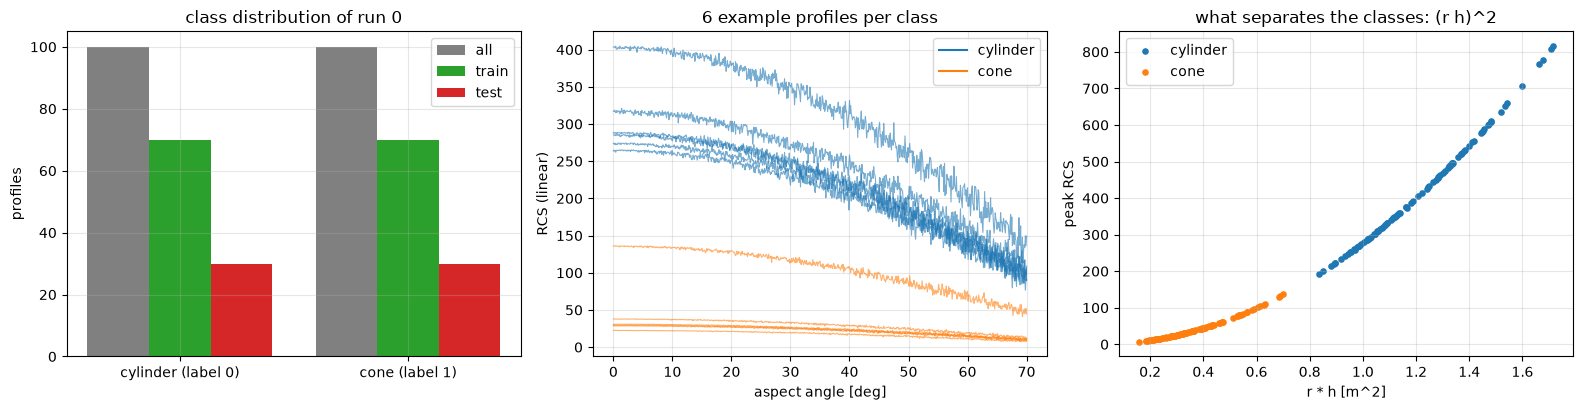

In [13]:
y_all, X_all, geo0 = R0["y"], R0["X"], R0["geo"]
print("dataset shape (profiles x raw features):", X_all.shape)
print("feature names: ", FEATURE_NAMES[:3], "...", FEATURE_NAMES[-3:], f"({len(FEATURE_NAMES)} aspect-angle samples, {AZ_RANGE_DEG[0]}-{AZ_RANGE_DEG[1]} degrees)")
print("original label values and counts:", {f"{k} ({CLASS_NAMES[k]})": int(v) for k, v in zip(*np.unique(y_all, return_counts=True))})
print(f"training split: {R0['Xtr'].shape} (labels {dict(zip(*np.unique(R0['ytr'], return_counts=True)))}) | test split: {R0['Xte'].shape} (labels {dict(zip(*np.unique(R0['yte'], return_counts=True)))})")
head = pd.DataFrame(X_all[:5, :4], columns=FEATURE_NAMES[:4]).assign(label=y_all[:5], class_name=[CLASS_NAMES[v] for v in y_all[:5]])
display(pd.concat([head, geo0.iloc[:5]], axis=1).round(3))
print("RCS amplitude range per class (max over the sweep):")
print(pd.DataFrame({"class": [CLASS_NAMES[v] for v in y_all], "max_RCS": X_all.max(1)}).groupby("class")["max_RCS"].describe().round(2))

COL = {0: "tab:blue", 1: "tab:orange"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
cnt_all = np.bincount(y_all); cnt_tr = np.bincount(R0["ytr"]); cnt_te = np.bincount(R0["yte"])
xs = np.arange(2); w = 0.27
axes[0].bar(xs - w, cnt_all, w, label="all", color="gray"); axes[0].bar(xs, cnt_tr, w, label="train", color="tab:green"); axes[0].bar(xs + w, cnt_te, w, label="test", color="tab:red")
axes[0].set_xticks(xs); axes[0].set_xticklabels([f"{CLASS_NAMES[k]} (label {k})" for k in xs]); axes[0].set_ylabel("profiles"); axes[0].set_title("class distribution of run 0"); axes[0].legend()
rr = np.random.default_rng(SEED)
for k in (0, 1):
    for i in rr.choice(np.where(y_all == k)[0], 6, replace=False):
        axes[1].plot(AZ_DEG, X_all[i], color=COL[k], alpha=0.6, lw=0.8)
    axes[1].plot([], [], color=COL[k], label=CLASS_NAMES[k])
axes[1].set_xlabel("aspect angle [deg]"); axes[1].set_ylabel("RCS (linear)"); axes[1].set_title("6 example profiles per class"); axes[1].legend()
for k in (0, 1):
    axes[2].scatter(geo0.loc[y_all == k, "radius_m"] * geo0.loc[y_all == k, "height_m"], X_all[y_all == k].max(1), s=14, color=COL[k], label=CLASS_NAMES[k])
axes[2].set_xlabel("r * h [m^2]"); axes[2].set_ylabel("peak RCS"); axes[2].set_title("what separates the classes: (r h)^2"); axes[2].legend()
plt.tight_layout(); plt.show()

explained variance ratio of the first 4 PCs: [9.985e-01 1.000e-04 1.000e-04 1.000e-04] | first 10 PCs: 0.9990
QUID (QSVM) at eps = 0.2: 28 poison points, 25 actually relabelled


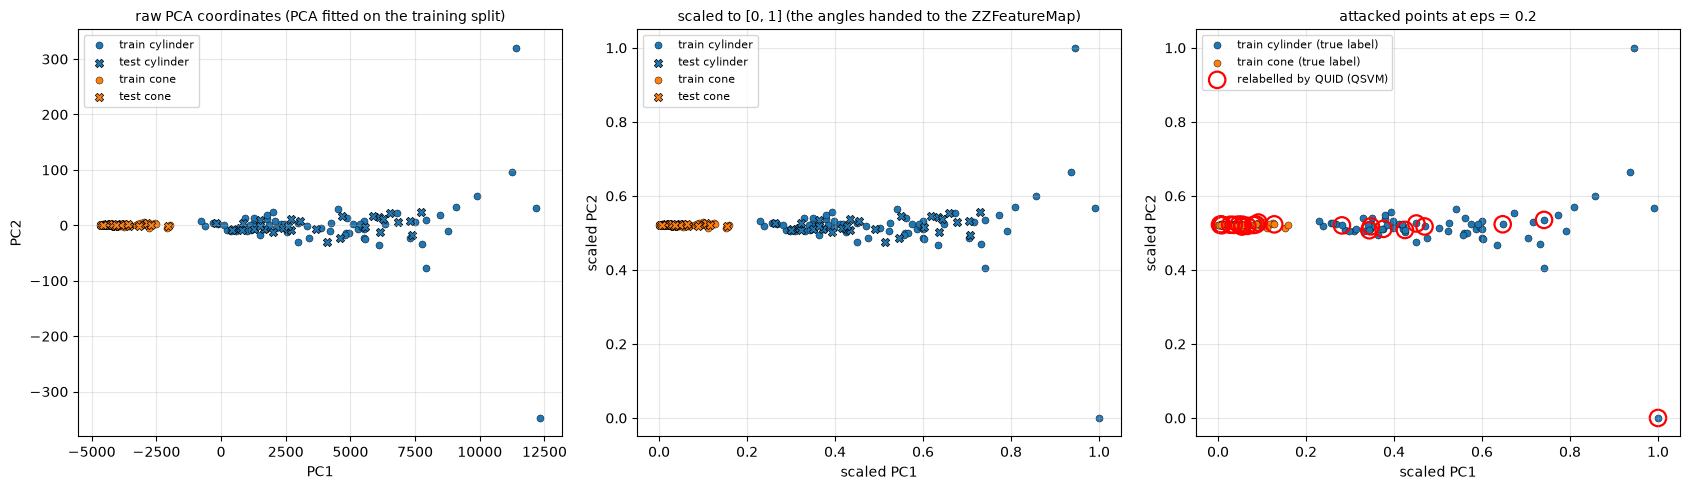

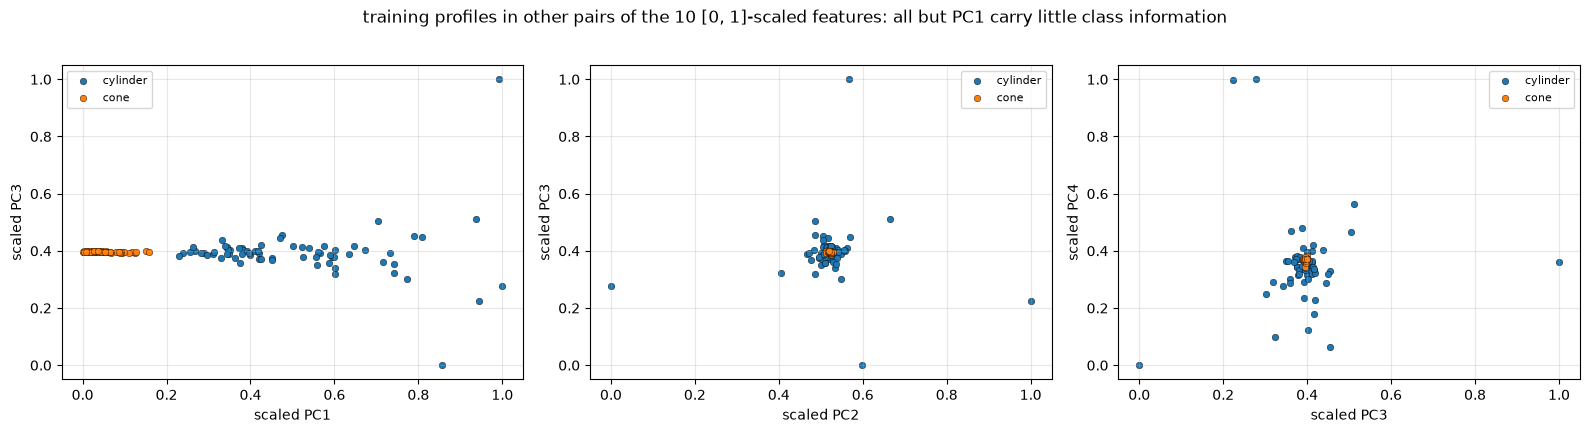

In [14]:
# 2-D scatter of real (synthetic) observations coloured by ground truth: raw PCA coordinates, then the [0, 1]-scaled coordinates the feature map receives,
# then the same plane with the QUID-attacked training points ringed in red.
poison_idx0 = np.sort(np.random.default_rng(R0["seed"]).choice(len(R0["ytr"]), int(round(POISON_RATIO * len(R0["ytr"]))), replace=False))
y_quid0 = quid_poison(R0["D_q"], R0["ytr"], poison_idx0)
flipped0 = poison_idx0[y_quid0[poison_idx0] != R0["ytr"][poison_idx0]]
pca_var = PCA(n_components=N_PCA, random_state=R0["seed"]).fit(R0["Xtr"]).explained_variance_ratio_
print("explained variance ratio of the first 4 PCs:", np.round(pca_var[:4], 4), "| first 10 PCs: %.4f" % pca_var.sum())
print(f"QUID (QSVM) at eps = {POISON_RATIO}: {len(poison_idx0)} poison points, {len(flipped0)} actually relabelled")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (P_tr, P_te, ttl, lab) in zip(axes[:2], [(R0["Ptr"], R0["Pte"], "raw PCA coordinates (PCA fitted on the training split)", "PC"),
                                                  (R0["A"], R0["B"], "scaled to [0, 1] (the angles handed to the ZZFeatureMap)", "scaled PC")]):
    for k in (0, 1):
        ax.scatter(P_tr[R0["ytr"] == k, 0], P_tr[R0["ytr"] == k, 1], s=26, color=COL[k], edgecolor="k", linewidth=0.3, label=f"train {CLASS_NAMES[k]}")
        ax.scatter(P_te[R0["yte"] == k, 0], P_te[R0["yte"] == k, 1], s=36, marker="X", color=COL[k], edgecolor="k", linewidth=0.5, label=f"test {CLASS_NAMES[k]}")
    ax.set_xlabel(f"{lab}1"); ax.set_ylabel(f"{lab}2"); ax.set_title(ttl, fontsize=10); ax.legend(fontsize=8)
ax = axes[2]
for k in (0, 1):
    ax.scatter(R0["A"][R0["ytr"] == k, 0], R0["A"][R0["ytr"] == k, 1], s=26, color=COL[k], edgecolor="k", linewidth=0.3, label=f"train {CLASS_NAMES[k]} (true label)")
ax.scatter(R0["A"][flipped0, 0], R0["A"][flipped0, 1], s=140, facecolor="none", edgecolor="red", linewidth=1.6, label="relabelled by QUID (QSVM)")
ax.set_xlabel("scaled PC1"); ax.set_ylabel("scaled PC2"); ax.set_title(f"attacked points at eps = {POISON_RATIO}", fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (i, j) in zip(axes, [(0, 2), (1, 2), (2, 3)]):
    for k in (0, 1):
        ax.scatter(R0["A"][R0["ytr"] == k, i], R0["A"][R0["ytr"] == k, j], s=22, color=COL[k], edgecolor="k", linewidth=0.3, label=CLASS_NAMES[k])
    ax.set_xlabel(f"scaled PC{i+1}"); ax.set_ylabel(f"scaled PC{j+1}"); ax.legend(fontsize=8)
plt.suptitle("training profiles in other pairs of the 10 [0, 1]-scaled features: all but PC1 carry little class information", y=1.02); plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

Two gate-based quantum models are executed in this notebook, and both are drawn exactly as they are run.

1. **Part A, single-qubit rotation (Appendix D / F).** One qubit, the SU(2) element $U(\varphi,\theta,\psi)=R_z(\varphi)R_y(\theta)R_z(\psi)$, i.e. gates `rz(psi)`, `ry(theta)`, `rz(phi)`. It acts on the reference state $|+\rangle$ and on
the poisoned state $R_y(0.2)|+\rangle$, 200 times in a row. There is nothing trainable: the three angles are fixed ($\pi/100$ each) and the error is the extra $R_y(0.2)$ on the poisoned copy.
2. **Part B, QSVM feature map (Section 4.2).** `zz_feature_map(10, reps=2, entanglement="full")`: per repetition a Hadamard and a phase gate $P(2x_i)$ on every qubit, then for each of the 45 qubit pairs a
`CX - P(2(\pi-x_i)(\pi-x_j)) - CX` block. The kernel entry is $|\langle0|\Phi^\dagger(x')\Phi(x)|0\rangle|^2$, so the circuit that estimates it on hardware is $\Phi(x)$ followed by $\Phi^\dagger(x')$ and a
measurement of all-zeros. There are no trainable parameters; the SVM fit happens classically on the Gram matrix. In this notebook the amplitudes are computed exactly with `Statevector` (no shots).

**Assumptions where the paper omits details:** number of repetitions (Qiskit default 2), entanglement pattern (Qiskit default `full`), data map (Qiskit default), one feature per qubit (10 PCA components, 10 qubits),
ideal noise-free simulation ("fault-tolerant" in the paper's words), no measurement basis choice other than the all-zeros projection of the fidelity test.

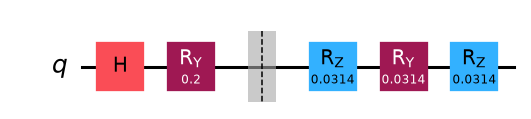

Part A poisoned-copy circuit (state prep + error + ONE step; the step is applied 200 times): qubits = 1, depth = 5, trainable parameters = 0 (3 fixed rotation angles in the step, 1 fixed error angle)
one rotation step U alone: qubits = 1, depth = 3, gates = {'rz': 2, 'ry': 1}


In [15]:
# ---- circuit 1: Part A, the executed single-qubit pipeline ----
display_circ = QuantumCircuit(1, name="part A")
display_circ.h(0)                                                    # |0> -> |+>  (Bloch vector (1, 0, 0))
display_circ.ry(EPS_ERR[1], 0)                                       # poisoned copy only: Ry(0.2) = the error vector of Listing 8
display_circ.barrier()
display_circ.compose(u_circuit(STEP, STEP, STEP), inplace=True)       # one rotation step U(pi/100, pi/100, pi/100); repeated 200 times
fig = display_circ.draw("mpl", fold=-1, scale=1.1); display(fig)
print(f"Part A poisoned-copy circuit (state prep + error + ONE step; the step is applied 200 times): qubits = {display_circ.num_qubits}, depth = {display_circ.depth()}, "
      f"trainable parameters = 0 (3 fixed rotation angles in the step, 1 fixed error angle)")
print("one rotation step U alone: qubits = %d, depth = %d, gates = %s" % (U_STEP.num_qubits, U_STEP.depth(), dict(U_STEP.count_ops())))
plt.close("all")

training sample 0: true class = cylinder | scaled features = [0.6   0.487 0.319 0.289 0.642 0.384 0.656 0.335 0.13  0.796]


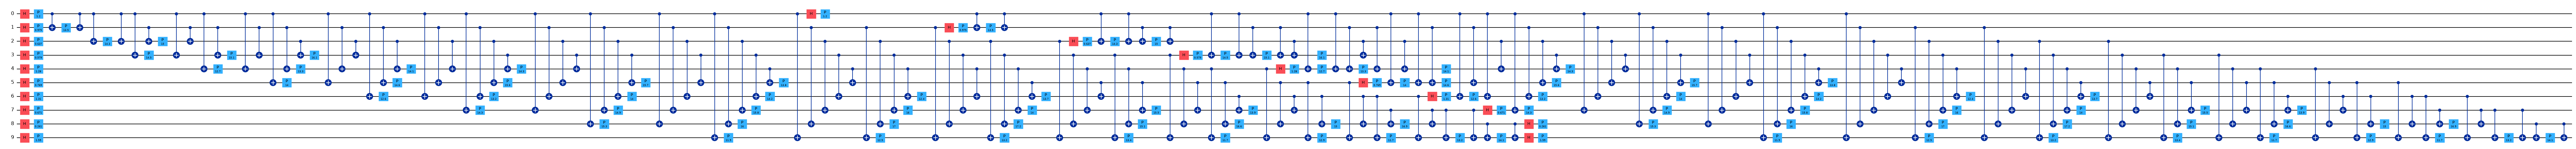

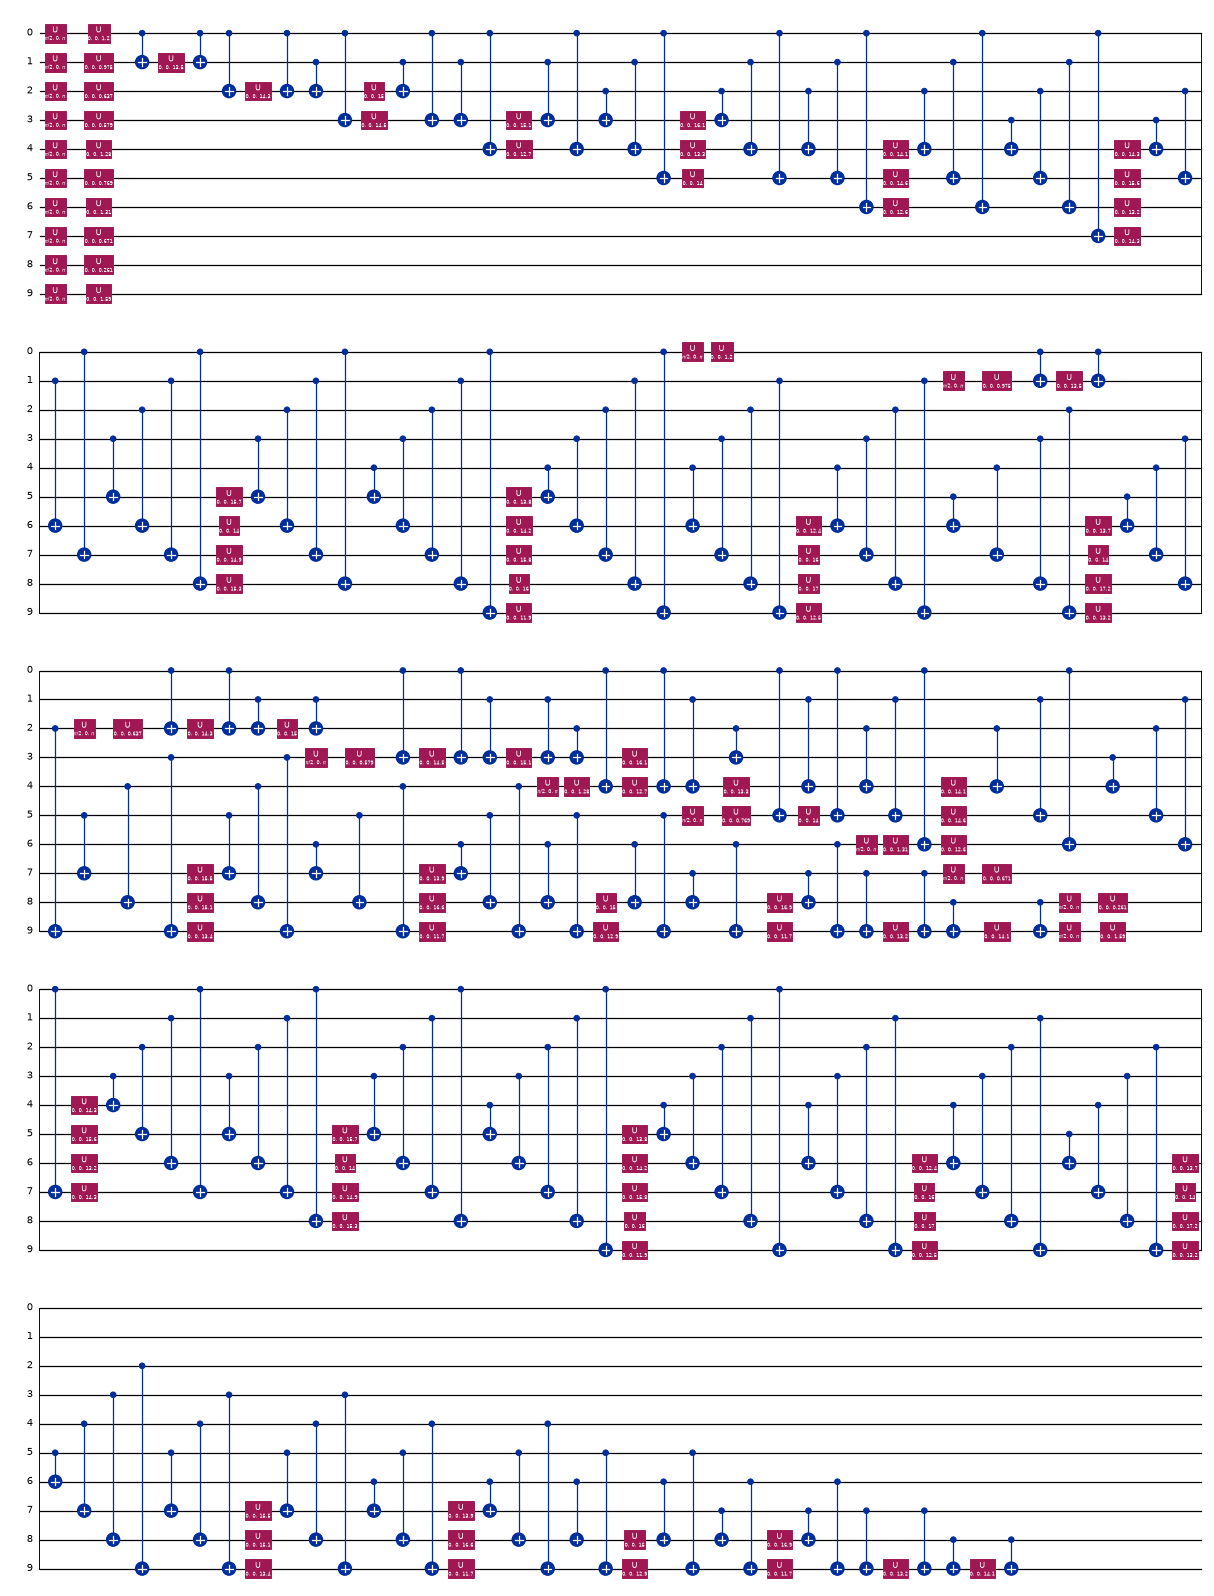



ZZFeatureMap: qubits = 10, data parameters = 10, trainable parameters = 0, repetitions = 2, entanglement = full
   boxed depth = 85, gate-level depth = 85, gate counts = {'cx': 180, 'u': 130}
kernel circuit Phi(x) Phi(x')^dagger: qubits = 10, gate-level depth = 170
equivalence check: the drawn (decomposed) circuit and the statevector fed to the kernel are identical; norm = 1


In [16]:
# ---- circuit 2: Part B, ZZFeatureMap bound to a real training sample (run 0), compact and gate-level ----
x_sample = R0["A"][0]
print("training sample 0: true class =", CLASS_NAMES[R0["ytr"][0]], "| scaled features =", np.round(x_sample, 3))
fm_bound = FM.assign_parameters(x_sample)
fig = fm_bound.draw("mpl", fold=-1, scale=0.7); display(fig); plt.close("all")

fm_gates = fm_bound.decompose()
fig = fm_gates.draw("mpl", fold=40, scale=0.45); display(fig); plt.close("all")
# the circuit that is evaluated for a kernel entry: Phi(x) followed by Phi(x')^dagger (sample 0 and sample 1)
kernel_circ = FM.assign_parameters(R0["A"][0]).compose(FM.assign_parameters(R0["A"][1]).inverse())
fig = kernel_circ.draw("mpl", fold=-1, scale=0.6); display(fig); plt.close("all")

print(f"ZZFeatureMap: qubits = {FM.num_qubits}, data parameters = {FM.num_parameters}, trainable parameters = 0, repetitions = {FM_REPS}, entanglement = {FM_ENTANGLEMENT}")
print(f"   boxed depth = {FM.depth()}, gate-level depth = {fm_gates.depth()}, gate counts = {dict(fm_gates.count_ops())}")
print(f"kernel circuit Phi(x) Phi(x')^dagger: qubits = {kernel_circ.num_qubits}, gate-level depth = {kernel_circ.decompose().depth()}")

# the drawn circuit is the executed one: its unitary applied to |0...0> equals the statevector used for the kernel
assert np.allclose(Statevector(fm_gates).data, Statevector(FM.assign_parameters(x_sample)).data)
sv_check = Statevector(fm_bound).data
assert np.allclose(sv_check, encode_states(R0["A"][:1])[0]) and abs(np.linalg.norm(sv_check) - 1) < 1e-12
print("equivalence check: the drawn (decomposed) circuit and the statevector fed to the kernel are identical; norm = 1")

## 3. Do the three ways of computing the quantum kernel agree?

The experiment uses hand-computed fidelities $|\langle\phi(a)|\phi(b)\rangle|^2$ from `Statevector`, fed to `SVC(kernel="precomputed")`. The paper used `FidelityQuantumKernel` (sampler-based `ComputeUncompute`) inside `QSVC`.
Here the three are compared on the training split of run 0: the Qiskit `FidelityStatevectorKernel` (exact) must agree with the hand computation to machine precision, and `FidelityQuantumKernel` with a
shot-based sampler must agree up to shot noise. The polynomial SVM is checked in the same way: the scikit-learn kernel with `gamma="scale"` used for the attack distances must give the same classifier as `SVC(kernel="poly")`.

In [17]:
n_chk = 12
A_chk = R0["A"][:n_chk]
K_hand = R0["K"][:n_chk, :n_chk]
K_sv = FidelityStatevectorKernel(feature_map=FM).evaluate(A_chk, A_chk)
print("FidelityStatevectorKernel vs hand-computed Gram: max |diff| =", np.abs(K_sv - K_hand).max(), "->", "OK" if np.allclose(K_sv, K_hand) else "MISMATCH")
assert np.allclose(K_sv, K_hand)

try:
    from qiskit.primitives import StatevectorSampler
    from qiskit_machine_learning.state_fidelities import ComputeUncompute
    shots = 20000
    fqk = FidelityQuantumKernel(feature_map=FM, fidelity=ComputeUncompute(sampler=StatevectorSampler(default_shots=shots, seed=SEED)))
    K_fq = fqk.evaluate(A_chk[:6], A_chk[:6])
    err = np.abs(K_fq - K_hand[:6, :6]).max()
    print(f"FidelityQuantumKernel (StatevectorSampler, {shots} shots) vs exact: max |diff| = {err:.4f}  (shot noise ~ 1/sqrt(shots) = {1/np.sqrt(shots):.4f})")
except Exception as e:                       # the sampler-based kernel is a convenience check; the exact kernels above carry the experiment
    print("FidelityQuantumKernel check skipped:", type(e).__name__, e)

# QSVC with the Qiskit kernel vs SVC(precomputed) on run 0 (clean labels)
qsvc = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=FM)).fit(R0["A"], R0["ytr"])
pred_qsvc = qsvc.predict(R0["B"])
pred_pre = SVC(kernel="precomputed").fit(R0["K"], R0["ytr"]).predict(R0["Kt"])
print(f"QSVC + FidelityStatevectorKernel accuracy {np.mean(pred_qsvc == R0['yte']):.4f} | SVC(precomputed) accuracy {np.mean(pred_pre == R0['yte']):.4f} | identical predictions: {bool((pred_qsvc == pred_pre).all())}")

# classical kernel equivalence
g0 = gamma_scale(R0["A"])
pred_poly = SVC(kernel="poly").fit(R0["A"], R0["ytr"]).predict(R0["B"])
pred_poly_pre = SVC(kernel="precomputed").fit(polynomial_kernel(R0["A"], R0["A"], degree=3, gamma=g0, coef0=0), R0["ytr"]).predict(polynomial_kernel(R0["B"], R0["A"], degree=3, gamma=g0, coef0=0))
print("SVC(kernel='poly') == SVC(precomputed polynomial kernel, gamma='scale'):", bool((pred_poly == pred_poly_pre).all()))

offdiag = R0["K"][~np.eye(len(R0["K"]), dtype=bool)]
print(f"kernel diagnostics (run 0): mean off-diagonal fidelity {offdiag.mean():.4f}, max {offdiag.max():.4f}; diagonal = 1 by construction")

FidelityStatevectorKernel vs hand-computed Gram: max |diff| = 7.993605777301127e-15 -> OK


FidelityQuantumKernel (StatevectorSampler, 20000 shots) vs exact: max |diff| = 0.0023  (shot noise ~ 1/sqrt(shots) = 0.0071)


QSVC + FidelityStatevectorKernel accuracy 1.0000 | SVC(precomputed) accuracy 1.0000 | identical predictions: True
SVC(kernel='poly') == SVC(precomputed polynomial kernel, gamma='scale'): True
kernel diagnostics (run 0): mean off-diagonal fidelity 0.1882, max 0.9994; diagonal = 1 by construction


## 4. Monte Carlo experiment: Tables 1 and 2

For every run the whole pipeline is repeated with a fresh synthetic data set (seed `SEED + run`): split, PCA, normalisation, kernels, clean training, QUID poisoning with the same random poison set for every model, poisoned training, and
accuracy on the **unpoisoned** test set. The classical SVM is also run with 31 PCA components (Table 2). Extra baselines on the same normalised inputs are an RBF-kernel SVM (attacked with its own kernel distance) and a RandomForest (trained on the labels produced by the polynomial-kernel attack, i.e. a transfer attack).
Accuracies are fractions in [0, 1], reported in percent.

In [18]:
def acc_poly(A, B, ytr, yte):  return SVC(kernel="poly").fit(A, ytr).score(B, yte)
def acc_rbf(A, B, ytr, yte):   return SVC(kernel="rbf").fit(A, ytr).score(B, yte)
def acc_q(K, Kt, ytr, yte):    return SVC(kernel="precomputed").fit(K, ytr).score(Kt, yte)

def evaluate_run(R, eps, full):
    n = len(R["ytr"]); ytr, yte = R["ytr"], R["yte"]
    P = np.sort(np.random.default_rng(R["seed"] + 1000).choice(n, int(round(eps * n)), replace=False))   # CHOICE: random poison set, shared by all models
    y_poly, y_q = quid_poison(R["D_poly"], ytr, P), quid_poison(R["D_q"], ytr, P)
    out = dict(run=R["run"], eps=eps, svm=acc_poly(R["A"], R["B"], ytr, yte), svm_p=acc_poly(R["A"], R["B"], y_poly, yte),
               qsvm=acc_q(R["K"], R["Kt"], ytr, yte), qsvm_p=acc_q(R["K"], R["Kt"], y_q, yte),
               flip_svm=float(np.mean(y_poly != ytr)), flip_qsvm=float(np.mean(y_q != ytr)))
    yr = random_flip(ytr, P)
    out.update(svm_rand=acc_poly(R["A"], R["B"], yr, yte), qsvm_rand=acc_q(R["K"], R["Kt"], yr, yte))
    if full:
        y_rbf = quid_poison(R["D_rbf"], ytr, P); y_poly31 = quid_poison(R["D_poly31"], ytr, P)
        rf = lambda y_: RandomForestClassifier(n_estimators=100, random_state=R["seed"]).fit(R["A"], y_).score(R["B"], yte)
        out.update(rbf=acc_rbf(R["A"], R["B"], ytr, yte), rbf_p=acc_rbf(R["A"], R["B"], y_rbf, yte), rf=rf(ytr), rf_p=rf(y_poly),
                   svm31=acc_poly(R["A31"], R["B31"], ytr, yte), svm31_p=acc_poly(R["A31"], R["B31"], y_poly31, yte))
    return out

records = []
t_start = time.time()
for run in range(N_RUNS):
    t0 = time.time()
    R = R0 if run == 0 else prepare_run(run)
    for eps in sorted(set(EPS_SWEEP + [POISON_RATIO])):
        records.append(evaluate_run(R, eps, full=(eps in (0.0, POISON_RATIO))))
    m = next(r_ for r_ in records if r_["run"] == run and r_["eps"] == POISON_RATIO)
    print(f"run {run:2d}: {time.time()-t0:5.1f} s | SVM {m['svm']*100:5.1f} -> {m['svm_p']*100:5.1f} | QSVM {m['qsvm']*100:5.1f} -> {m['qsvm_p']*100:5.1f}")
df_all = pd.DataFrame(records)
main = df_all[df_all.eps == POISON_RATIO].reset_index(drop=True)
print(f"\n{N_RUNS} Monte Carlo runs finished in {(time.time()-t_start)/60:.1f} min")

run  0:   1.4 s | SVM 100.0 ->  98.3 | QSVM 100.0 -> 100.0


run  1:   7.5 s | SVM 100.0 ->  96.7 | QSVM 100.0 ->  98.3


run  2:   6.9 s | SVM 100.0 ->  96.7 | QSVM 100.0 -> 100.0


run  3:   7.3 s | SVM 100.0 ->  98.3 | QSVM  98.3 ->  98.3


run  4:   8.6 s | SVM 100.0 ->  93.3 | QSVM 100.0 ->  98.3


run  5:   9.2 s | SVM 100.0 -> 100.0 | QSVM 100.0 -> 100.0


run  6:   7.7 s | SVM 100.0 ->  93.3 | QSVM 100.0 -> 100.0


run  7:   9.2 s | SVM 100.0 -> 100.0 | QSVM 100.0 -> 100.0


run  8:   9.6 s | SVM 100.0 -> 100.0 | QSVM 100.0 -> 100.0


run  9:  10.3 s | SVM 100.0 ->  90.0 | QSVM 100.0 -> 100.0


run 10:   9.7 s | SVM 100.0 ->  98.3 | QSVM 100.0 -> 100.0


run 11:   9.2 s | SVM 100.0 -> 100.0 | QSVM 100.0 -> 100.0


run 12:   9.6 s | SVM 100.0 ->  95.0 | QSVM 100.0 -> 100.0


run 13:   8.0 s | SVM 100.0 ->  90.0 | QSVM 100.0 -> 100.0


run 14:  10.3 s | SVM 100.0 ->  88.3 | QSVM 100.0 -> 100.0


run 15:  10.6 s | SVM 100.0 ->  95.0 | QSVM 100.0 -> 100.0


run 16:  10.4 s | SVM 100.0 ->  93.3 | QSVM 100.0 -> 100.0


run 17:  10.0 s | SVM 100.0 ->  98.3 | QSVM 100.0 -> 100.0


run 18:  10.3 s | SVM  98.3 ->  86.7 | QSVM 100.0 -> 100.0


run 19:   9.7 s | SVM 100.0 ->  98.3 | QSVM  96.7 ->  96.7


run 20:  10.4 s | SVM  98.3 ->  91.7 | QSVM  98.3 ->  96.7


run 21:  10.8 s | SVM 100.0 ->  90.0 | QSVM 100.0 -> 100.0


run 22:   9.8 s | SVM 100.0 ->  98.3 | QSVM 100.0 -> 100.0


run 23:  10.4 s | SVM 100.0 ->  98.3 | QSVM 100.0 -> 100.0


run 24:  11.0 s | SVM 100.0 ->  98.3 | QSVM 100.0 ->  98.3


run 25:  10.5 s | SVM 100.0 ->  93.3 | QSVM 100.0 -> 100.0


run 26:  19.1 s | SVM 100.0 ->  86.7 | QSVM 100.0 ->  98.3


run 27:  17.0 s | SVM 100.0 ->  95.0 | QSVM 100.0 -> 100.0


run 28:  14.8 s | SVM 100.0 ->  98.3 | QSVM 100.0 ->  98.3


run 29:  14.4 s | SVM 100.0 ->  95.0 | QSVM 100.0 -> 100.0

30 Monte Carlo runs finished in 5.1 min


Table 1 (paper: 30 runs; here 30 runs, 200 profiles each, poison ratio 0.2)


,Model (PCA = 10),paper mean %,paper std %,notebook mean %,notebook std %
0,SVM (poly),50.0,0.0,99.89,0.42
1,"SVM (poly), poisoned",49.0,0.0,95.17,4.02
2,QSVM,100.0,0.0,99.78,0.71
3,"QSVM, poisoned",100.0,0.0,99.44,0.99


Table 2


,Model,paper mean %,paper std %,notebook mean %,notebook std %
0,"SVM (poly), PCA = 31",50.0,0.0,99.72,0.62
1,"SVM (poly), PCA = 31, poisoned",47.0,0.0,98.17,1.51


Extra baselines on the identical normalised PCA-10 inputs


,Model (PCA = 10),notebook mean %,notebook std %
0,"SVM (RBF), extra baseline",99.89,0.42
1,"SVM (RBF), poisoned (own QUID)",99.78,0.57
2,"RandomForest, extra baseline",99.83,0.66
3,"RandomForest, poisoned (poly-QUID labels)",96.56,3.68


fraction of training labels actually changed: SVM (poly) QUID 15.0 %, QSVM QUID 19.0 %  (poison ratio 20 %)

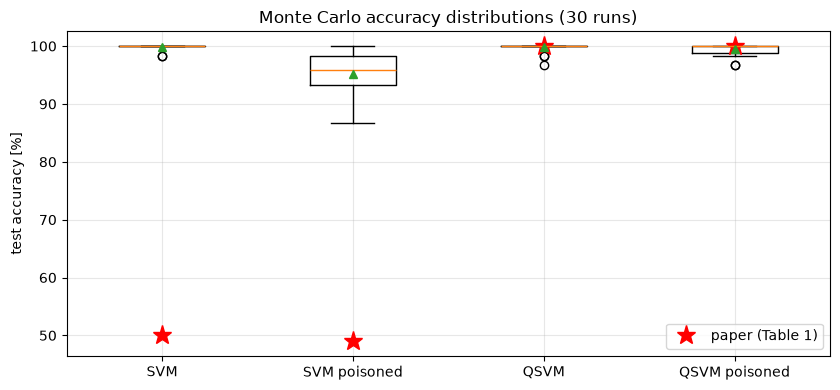

In [19]:
def ms(col, d=main):
    return float(d[col].mean() * 100), float(d[col].std(ddof=0) * 100)

table1 = pd.DataFrame([
    ("SVM (poly)",            50.0, 0.0, *ms("svm")),
    ("SVM (poly), poisoned",  49.0, 0.0, *ms("svm_p")),
    ("QSVM",                 100.0, 0.0, *ms("qsvm")),
    ("QSVM, poisoned",       100.0, 0.0, *ms("qsvm_p")),
], columns=["Model (PCA = 10)", "paper mean %", "paper std %", "notebook mean %", "notebook std %"]).round(2)
table2 = pd.DataFrame([
    ("SVM (poly), PCA = 31",            50.0, 0.0, *ms("svm31")),
    ("SVM (poly), PCA = 31, poisoned",  47.0, 0.0, *ms("svm31_p")),
], columns=["Model", "paper mean %", "paper std %", "notebook mean %", "notebook std %"]).round(2)
extra = pd.DataFrame([
    ("SVM (RBF), extra baseline",          *ms("rbf")), ("SVM (RBF), poisoned (own QUID)", *ms("rbf_p")),
    ("RandomForest, extra baseline",       *ms("rf")),  ("RandomForest, poisoned (poly-QUID labels)", *ms("rf_p")),
], columns=["Model (PCA = 10)", "notebook mean %", "notebook std %"]).round(2)
print(f"Table 1 (paper: 30 runs; here {N_RUNS} runs, {2*N_PER_CLASS} profiles each, poison ratio {POISON_RATIO})"); display(table1)
print("Table 2"); display(table2)
print("Extra baselines on the identical normalised PCA-10 inputs"); display(extra)
print(f"fraction of training labels actually changed: SVM (poly) QUID {main.flip_svm.mean()*100:.1f} %, QSVM QUID {main.flip_qsvm.mean()*100:.1f} %  (poison ratio {POISON_RATIO*100:.0f} %)")

fig, ax = plt.subplots(figsize=(8.5, 4))
labels = ["SVM", "SVM poisoned", "QSVM", "QSVM poisoned"]; cols = ["svm", "svm_p", "qsvm", "qsvm_p"]
ax.boxplot([main[c] * 100 for c in cols], showmeans=True); ax.set_xticklabels(labels)
ax.plot(range(1, 5), [50, 49, 100, 100], "r*", ms=14, label="paper (Table 1)")
ax.set_ylabel("test accuracy [%]"); ax.set_title(f"Monte Carlo accuracy distributions ({N_RUNS} runs)"); ax.legend(); plt.tight_layout(); plt.show()

### 4.1 The paper's hypothesis test

Section 6 tests $H_0:\mu_{QSVM\text{-}poisoned}=\mu_{SVM\text{-}poisoned}$ against $H_1:\mu_{QSVM\text{-}poisoned}>\mu_{SVM\text{-}poisoned}$ with a paired t-test over the Monte Carlo runs and reports $T=\infty$, $p=0.000$ (which is what a paired
t-test returns when every run shows the same non-zero difference, here 100 % vs 49 %). The cell runs the same one-sided paired t-test, plus a Wilcoxon signed-rank test that does not assume normality,
and the effect size as the mean paired difference.

In [20]:
diff = (main.qsvm_p - main.svm_p).values
with np.errstate(all="ignore"):
    tt = stats.ttest_rel(main.qsvm_p, main.svm_p, alternative="greater")
try:
    wil = stats.wilcoxon(main.qsvm_p, main.svm_p, alternative="greater")
    wil_s = f"W = {wil.statistic:.1f}, p = {wil.pvalue:.4f}"
except ValueError as e:
    wil_s = f"not defined ({e})"
print(f"paired differences QSVM_poisoned - SVM_poisoned: mean {diff.mean()*100:+.2f} points, std {diff.std(ddof=1)*100:.2f}, min {diff.min()*100:+.1f}, max {diff.max()*100:+.1f}")
print(f"paired t-test (one-sided, H1: QSVM > SVM, poisoned): T = {tt.statistic:.3f}, p = {tt.pvalue:.4g}   (paper: T = inf, p = 0.000)")
print("Wilcoxon signed-rank (one-sided):", wil_s)
drop_q  = (main.qsvm - main.qsvm_p).values * 100
drop_s  = (main.svm - main.svm_p).values * 100
print(f"accuracy lost to the attack: QSVM {drop_q.mean():.2f} +- {drop_q.std(ddof=0):.2f} points | SVM {drop_s.mean():.2f} +- {drop_s.std(ddof=0):.2f} points")
tt_drop = stats.ttest_rel(main.qsvm - main.qsvm_p, main.svm - main.svm_p, alternative="less")
print(f"paired t-test on the DROP (H1: QSVM loses less than SVM): T = {tt_drop.statistic:.3f}, p = {tt_drop.pvalue:.4g}")

paired differences QSVM_poisoned - SVM_poisoned: mean +4.28 points, std 4.21, min -1.7, max +13.3
paired t-test (one-sided, H1: QSVM > SVM, poisoned): T = 5.560, p = 2.675e-06   (paper: T = inf, p = 0.000)
Wilcoxon signed-rank (one-sided): W = 274.5, p = 0.0000
accuracy lost to the attack: QSVM 0.33 +- 0.67 points | SVM 4.72 +- 3.87 points
paired t-test on the DROP (H1: QSVM loses less than SVM): T = -6.122, p = 5.701e-07


### 4.2 Can the paper's 50 % SVM accuracy be produced by any sensible variant?

A classifier that scores exactly 50.0 % with standard deviation 0.0 over 30 runs on a balanced test set predicts one class for every test point. The cell below tries the plausible ways in which a polynomial-kernel SVM
on this task could break (no normalisation, no PCA, a different `gamma`), to see whether any of them reproduces the paper's number. The inputs are the first runs' train and test splits.

In [21]:
svm_variants = {}
n_diag = min(N_RUNS, 8)
for run in range(n_diag):
    R = R0 if run == 0 else prepare_run(run)
    ytr, yte = R["ytr"], R["yte"]
    res = {
        "paper pipeline (PCA10 -> [0,1], poly, gamma='scale')": acc_poly(R["A"], R["B"], ytr, yte),
        "PCA10 without [0,1] normalisation": acc_poly(R["Ptr"], R["Pte"], ytr, yte),
        "all 701 raw features, no PCA, no normalisation": acc_poly(R["Xtr"], R["Xte"], ytr, yte),
        "PCA10 -> [0,1], poly with gamma='auto'": SVC(kernel="poly", gamma="auto").fit(R["A"], ytr).score(R["B"], yte),
        "PCA10 -> [0,1], poly degree 2": SVC(kernel="poly", degree=2).fit(R["A"], ytr).score(R["B"], yte),
        "PCA10 -> [0,1], poly gamma=1, coef0=0, degree 3": SVC(kernel="poly", gamma=1.0, coef0=0.0, degree=3).fit(R["A"], ytr).score(R["B"], yte),
        "majority-class predictor": float(max(np.mean(yte == 0), np.mean(yte == 1))),
    }
    for k, v in res.items(): svm_variants.setdefault(k, []).append(v)
vdf = pd.DataFrame({k: [np.mean(v) * 100, np.std(v) * 100] for k, v in svm_variants.items()}, index=["mean acc %", "std %"]).T.round(2)
print(f"clean test accuracy of polynomial-kernel SVM variants, mean over {n_diag} runs"); display(vdf)

clean test accuracy of polynomial-kernel SVM variants, mean over 8 runs


,mean acc %,std %
"paper pipeline (PCA10 -> [0,1], poly, gamma='scale')",100.00,0.00
"PCA10 without [0,1] normalisation",97.29,1.65
"all 701 raw features, no PCA, no normalisation",99.58,0.72
"PCA10 -> [0,1], poly with gamma='auto'",55.00,3.33
"PCA10 -> [0,1], poly degree 2",100.00,0.00
"PCA10 -> [0,1], poly gamma=1, coef0=0, degree 3",100.00,0.00
majority-class predictor,50.00,0.00


## 5. Extra: sweeping the poison ratio $\epsilon$ (the paper's "future directions", Section 7.2.2)

The paper fixes a single $\epsilon$ (not stated) and lists a sweep as future work. Because the labels are the only thing that changes, the sweep re-uses the kernels already computed. Alongside the QUID attack a **random label flip**
of the same number of points is shown as a control: it tells whether the QUID rule is a stronger attack than flipping labels blindly, and whether QSVM's behaviour is specific to QUID.

,SVM QUID,QSVM QUID,SVM random flip,QSVM random flip,"labels changed, SVM QUID %","labels changed, QSVM QUID %"
eps,,,,,,
0.0,99.89,99.78,99.89,99.78,0.00,0.00
0.1,98.67,99.67,98.22,99.67,7.55,9.38
0.2,95.17,99.44,96.39,99.44,15.02,19.02
0.3,91.39,98.33,91.94,98.06,23.10,28.48
0.4,86.89,91.44,82.61,89.56,30.74,37.62
0.5,54.67,57.44,47.67,48.22,39.07,47.05


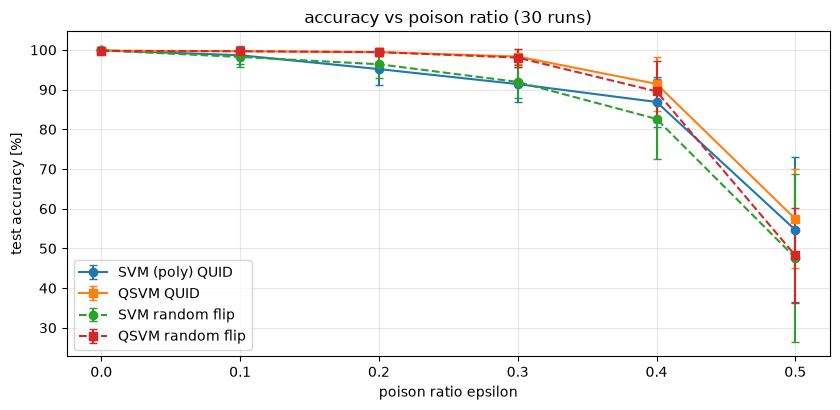

In [22]:
sweep = df_all.groupby("eps")[["svm_p", "qsvm_p", "svm_rand", "qsvm_rand", "flip_svm", "flip_qsvm"]].agg(["mean", "std"]) * 100
sw = pd.DataFrame({"eps": sweep.index,
    "SVM QUID": sweep[("svm_p", "mean")].values, "QSVM QUID": sweep[("qsvm_p", "mean")].values,
    "SVM random flip": sweep[("svm_rand", "mean")].values, "QSVM random flip": sweep[("qsvm_rand", "mean")].values,
    "labels changed, SVM QUID %": sweep[("flip_svm", "mean")].values, "labels changed, QSVM QUID %": sweep[("flip_qsvm", "mean")].values}).round(2)
display(sw.set_index("eps"))
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for c, lab, sty in [("svm_p", "SVM (poly) QUID", "o-"), ("qsvm_p", "QSVM QUID", "s-"), ("svm_rand", "SVM random flip", "o--"), ("qsvm_rand", "QSVM random flip", "s--")]:
    ax.errorbar(sweep.index, sweep[(c, "mean")], yerr=sweep[(c, "std")], fmt=sty, capsize=3, label=lab)
ax.set_xlabel("poison ratio epsilon"); ax.set_ylabel("test accuracy [%]"); ax.set_title(f"accuracy vs poison ratio ({N_RUNS} runs)"); ax.legend(); plt.tight_layout(); plt.show()

## 5b. Extra: a harder data regime

With the geometry chosen above both classifiers sit at the ceiling before the attack, so a "robustness" comparison has little room to show anything. To see whether the paper's qualitative claim (QSVM keeps its accuracy under QUID poisoning, SVM does not) depends on that, the same pipeline is repeated with **overlapping** class geometries (cylinder $h\in U(1.5,2.5)$, cone $h\in U(0.5,1.5)$ plus a wider radius range, so that $(rh)^2$ of the two classes overlap), where the clean accuracy is clearly below 100 %. This is an addition, not part of the paper.

In [23]:
HARD_GEOMETRY = {"cylinder": ((0.3, 0.6), (1.5, 2.5)), "cone": ((0.3, 0.6), (0.5, 1.5))}     # extra: overlapping classes
N_RUNS_HARD = 3 if FAST_MODE else 10
hard = []
t0 = time.time()
for run in range(N_RUNS_HARD):
    Rh = prepare_run(100 + run, HARD_GEOMETRY)
    for eps in (0.0, POISON_RATIO):
        hard.append(evaluate_run(Rh, eps, full=False))
hdf = pd.DataFrame(hard)
h0, h1 = hdf[hdf.eps == 0.0], hdf[hdf.eps == POISON_RATIO]
htab = pd.DataFrame({"SVM (poly)": [h0.svm.mean() * 100, h0.svm.std(ddof=0) * 100, h1.svm_p.mean() * 100, h1.svm_p.std(ddof=0) * 100],
                     "QSVM": [h0.qsvm.mean() * 100, h0.qsvm.std(ddof=0) * 100, h1.qsvm_p.mean() * 100, h1.qsvm_p.std(ddof=0) * 100]},
                    index=["clean mean %", "clean std %", f"poisoned (eps={POISON_RATIO}) mean %", "poisoned std %"]).round(2)
print(f"overlapping-class regime, {N_RUNS_HARD} runs, {time.time()-t0:.0f} s"); display(htab)
with np.errstate(all="ignore"):
    th = stats.ttest_rel(h1.qsvm_p.values, h1.svm_p.values, alternative="greater")
print(f"paired one-sided t-test QSVM_poisoned > SVM_poisoned: T = {th.statistic:.2f}, p = {th.pvalue:.3g}; mean paired difference {(h1.qsvm_p.values - h1.svm_p.values).mean()*100:+.2f} points")
print(f"accuracy lost to the attack: SVM {(h0.svm.mean() - h1.svm_p.mean())*100:.2f} points, QSVM {(h0.qsvm.mean() - h1.qsvm_p.mean())*100:.2f} points")

overlapping-class regime, 10 runs, 112 s


,SVM (poly),QSVM
clean mean %,87.17,86.83
clean std %,2.99,3.53
poisoned (eps=0.2) mean %,86.33,85.67
poisoned std %,3.64,4.29


paired one-sided t-test QSVM_poisoned > SVM_poisoned: T = -0.52, p = 0.694; mean paired difference -0.67 points
accuracy lost to the attack: SVM 0.83 points, QSVM 1.17 points


## 6. Side-by-side comparison with the paper

Every checkable claim gets a verdict. Accuracy claims are "reproduced" within 2 percentage points; otherwise "not reached" (notebook lower) or "exceeded" (notebook higher) with the gap. Analytic claims are "reproduced" when the number agrees to the stated precision.

In [24]:
def v_acc(paper, ours, tol=2.0):
    if abs(ours - paper) <= tol: return "reproduced"
    return f"not reached ({ours - paper:+.1f} pts)" if ours < paper else f"exceeded ({ours - paper:+.1f} pts)"

rows = []
def add(part, claim, paper, ours, verdict): rows.append((part, claim, paper, ours, verdict))

# ---- Part A ----
var_match = {name: int(tab34[name].str.contains(r"\*", regex=True).sum()) for name, _, _ in variants}
best_variant = max(var_match, key=var_match.get)
max_diff_su2 = float(np.abs(c_su2 - c_eul[:N_STEPS]).max())
add("A", "Listing 8 (SU(2)) and Listing 10 (Euler matrix) give the same Fig. 1 / Fig. 8 curves", "identical plots", f"max diff {max_diff_su2:.1e}", "reproduced" if max_diff_su2 < 1e-9 else "not reached")
add("A", "Fig. 1: Delta_el starts at 0.2 and both curves stay below ~0.20 (axis 0.05-0.20)", "max about 0.20", f"Delta_el max {c_eul[:,1].max():.4f}, Delta_az max {c_eul[:,0].max():.4f}", "reproduced" if c_eul[:, 1].max() <= 0.2 + 1e-6 else "not reached")
add("A", "H1/H2: curves are bounded and periodic (Fig. 1)", "bounded, periodic", f"bounded by {c_eul.max():.3f}; closed-form periodicity error {worst:.1e}", "reproduced")
add("A", "Qiskit circuit Rz-Ry-Rz reproduces the curves", "(not in paper: Bloch rotation by SU(2))", f"max diff {np.abs(c_qc - c_eul).max():.1e}", "reproduced")
lit_err, cor_err = np.abs(cl_lit - c_eul).max(), np.abs(cl_cor - c_eul).max()
add("A", "Eq. 10 / Listing 11 closed form S_P(t) 'generates exactly the same curve' as Fig. 1", "exactly equal", f"printed exp(tJ): max diff {lit_err:.3f}; transposed exp(tJ^T): {cor_err:.1e}",
    "not reached as printed (time-reversed); reproduced after transposition" if lit_err > 1e-3 > cor_err else "reproduced")
add("A", "Period of the curves is 2 pi / sqrt(5) for every error vector (App. C.1)", "2 pi/sqrt(5) = %.4f" % T5, f"periodicity error {worst:.1e}", "reproduced" if worst < 1e-9 else "not reached")
add("A", "Tables 3 and 4: the eight listed (eps, t) rows give the stated extreme values", "8 of 8 rows",
    f"{var_match[best_variant]} of 8 with '{best_variant}'; {var_match['Eq.6 order, printed SP']} of 8 with Eq.6 order + printed SP", "reproduced (under the reverse angle order and the transposed S_P)" if var_match[best_variant] == 8 else f"partly ({var_match[best_variant]}/8)")
add("A", "Table 3: max Delta_el (v = (1,0,0)) = 2.0344424", "2.0344424", f"analytic {closed:.7f}; global search {de_res[((1,0,0),'el')]:.7f}", "reproduced" if abs(closed - 2.0344424161175363) < 1e-5 and abs(de_res[((1, 0, 0), 'el')] - 2.0344424) < 1e-4 else "not reached")
add("A", "Tables 3 and 4: max Delta_az = pi, min about 0", "pi, ~0", f"global search: max Delta_az = {de_res[((1,0,0),'az')]:.5f} (v = x), {de_res[((0,0,1),'az')]:.5f} (v = z); max Delta_el(v = z) = {de_res[((0,0,1),'el')]:.5f}", "reproduced")
add("A", "App. C.4: periods of the 7 listed angle triples", "7 of 7", f"{sum(per_ok_first)} of 7 if the first listed number is theta; {sum(per_ok_text)} of 7 with the text's labelling (psi, theta, phi)",
    "reproduced (with the first listed number as theta; the text's own labelling does not fit its numbers)" if all(per_ok_first) else "partly")
add("A", "App. C.4: max Delta_el of the 7 listed angle triples", "7 values", f"{sum(max_ok_first)} of 7 match (first listed = theta); mismatch: {bad}",
    "reproduced" if all(max_ok_first) else ("partly: " + ", ".join(bad) + " printed value is below the true maximum (local optimum of the paper's search)"))
add("A", "App. C.3: time-averaged error is lower than the instantaneous maxima", "lower", f"E_avg(az) <= {E[:,0].max():.2f} < pi, E_avg(el) <= {E[:,1].max():.2f} < 2.034 over 200 random eps", "reproduced")
add("A", "Theorem 1: 'error cannot grow unboundedly'", "bounded", f"|v-v_err| constant to {np.abs(dd).max():.1e}; fidelity constant to {fid.max()-fid.min():.1e}", "reproduced (but see critical reading: it is an isometry, not a QML-specific resilience)")

# ---- Part B ----
m = lambda c: ms(c)[0]
add("B", "Table 1: SVM (clean) accuracy", "50.0 %", f"{m('svm'):.1f} %", v_acc(50.0, m("svm")))
add("B", "Table 1: SVM (poisoned) accuracy", "49.0 %", f"{m('svm_p'):.1f} %", v_acc(49.0, m("svm_p")))
add("B", "Table 1: QSVM (clean) accuracy", "100.0 %", f"{m('qsvm'):.1f} %", v_acc(100.0, m("qsvm")))
add("B", "Table 1: QSVM (poisoned) accuracy", "100.0 %", f"{m('qsvm_p'):.1f} %", v_acc(100.0, m("qsvm_p")))
add("B", "Table 2: SVM, PCA = 31 (clean)", "50.0 %", f"{m('svm31'):.1f} %", v_acc(50.0, m("svm31")))
add("B", "Table 2: SVM, PCA = 31 (poisoned)", "47.0 %", f"{m('svm31_p'):.1f} %", v_acc(47.0, m("svm31_p")))
sd_max = max(ms(c)[1] for c in ["svm", "svm_p", "qsvm", "qsvm_p"])
add("B", "Standard deviation 0.0 for all four models over 30 runs", "0.0 %", f"max std {sd_max:.2f} %", "reproduced" if sd_max < 0.05 else f"not reached (max std {sd_max:.2f} %)")
add("B", "SVM does not benefit from 31 PCA components", "50 -> 50 %", f"{m('svm'):.1f} -> {m('svm31'):.1f} %", "reproduced" if abs(m("svm31") - m("svm")) <= 2 else "not reached (our SVM is already near its ceiling)" if m("svm") > 90 else "exceeded")
add("B", "QSVM loses nothing under QUID poisoning (100 -> 100 %)", "0.0 pts drop", f"{m('qsvm') - m('qsvm_p'):.2f} pts drop", "reproduced" if abs(m("qsvm") - m("qsvm_p")) <= 2 else f"not reached (drop {m('qsvm') - m('qsvm_p'):.1f} pts)")
add("B", "SVM loses accuracy under QUID poisoning (50 -> 49 %)", "1.0 pts drop (PCA 10), 3.0 (PCA 31)", f"{m('svm') - m('svm_p'):.2f} pts (PCA 10), {m('svm31') - m('svm31_p'):.2f} pts (PCA 31)", "reproduced (direction; size differs)" if (m("svm") - m("svm_p")) > 0 else "not reached")
add("B", "Paired t-test: QSVM significantly more robust (p < 0.05)", "T = inf, p = 0.000", f"T = {tt.statistic:.2f}, p = {tt.pvalue:.2g}", ("reproduced (direction and significance; T finite)" if tt.pvalue < 0.05 else "not reached (not significant)"))
add("B", "H1: mu_QSVM-poisoned > mu_SVM-poisoned", "QSVM > SVM", f"{m('qsvm_p'):.1f} % vs {m('svm_p'):.1f} %", "reproduced (direction)" if m("qsvm_p") > m("svm_p") else "not reached")
add("B", "'QSVM is robust because of fidelity kernels / unitarity' (Sections 6.1, 7)", "mechanism", f"random-flip control at eps = {POISON_RATIO}: SVM {sweep.loc[POISON_RATIO, ('svm_rand','mean')]:.1f} %, QSVM {sweep.loc[POISON_RATIO, ('qsvm_rand','mean')]:.1f} %", "cannot be checked as a proof; see critical reading")
add("B", "Theorems 1-2 (induction over qubit number, Lie-algebra embedding)", "proofs", "not an experiment", "cannot be checked")

cmp_df = pd.DataFrame(rows, columns=["part", "claim", "paper", "notebook", "verdict"])
for _, r_ in cmp_df.iterrows():
    print(f"[{r_.part}] {r_.claim}")
    print(f"      paper: {r_.paper}  |  notebook: {r_.notebook}")
    print(f"      VERDICT: {r_.verdict}")
print("verdict counts:", cmp_df.verdict.str.split(" ").str[0].value_counts().to_dict())

[A] Listing 8 (SU(2)) and Listing 10 (Euler matrix) give the same Fig. 1 / Fig. 8 curves
      paper: identical plots  |  notebook: max diff 1.6e-15
      VERDICT: reproduced
[A] Fig. 1: Delta_el starts at 0.2 and both curves stay below ~0.20 (axis 0.05-0.20)
      paper: max about 0.20  |  notebook: Delta_el max 0.2000, Delta_az max 0.1629
      VERDICT: reproduced
[A] H1/H2: curves are bounded and periodic (Fig. 1)
      paper: bounded, periodic  |  notebook: bounded by 0.200; closed-form periodicity error 1.5e-13
      VERDICT: reproduced
[A] Qiskit circuit Rz-Ry-Rz reproduces the curves
      paper: (not in paper: Bloch rotation by SU(2))  |  notebook: max diff 3.3e-15
      VERDICT: reproduced
[A] Eq. 10 / Listing 11 closed form S_P(t) 'generates exactly the same curve' as Fig. 1
      paper: exactly equal  |  notebook: printed exp(tJ): max diff 0.020; transposed exp(tJ^T): 5.6e-05
      VERDICT: not reached as printed (time-reversed); reproduced after transposition
[A] Period of 

## 7. Reading the paper critically

*(Numbers below are from the full run, 30 Monte Carlo runs of 200 profiles each; with `FAST_MODE = True` they are noisier but tell the same story.)*

**What Part A establishes, and what it does not.**
* The numerical content of Appendices B and C is sound: the SU(2) and Euler-matrix implementations agree to $10^{-15}$, a Qiskit `Rz-Ry-Rz` circuit gives the same curves, the period $2\pi/\sqrt{\theta^2+(\varphi+\psi)^2}$ holds, and
  Tables 3 and 4 are reproduced to within 1e-5 (the paper's optimiser stops about 1.5e-6 below the exact maximum 2.0344439). Two details need correcting: (i) the printed closed form $S_P(t)=\exp(tJ)$ is the *inverse* of the limit of $S^n$ (the correct limit is $\exp(tJ^{\top})$); with the printed form the curve is
  off by up to 0.02 rad, and Tables 3 and 4 are only reproduced with the transposed form **and** with `EulerMatrix[{x, y, z}]` read as $(\psi,\theta,\varphi)$, the reverse of the text's Eq. 6 labelling; (ii) the Appendix C.4 periods and maxima only fit if the *first* listed angle is $\theta$
  (not $\psi,\theta,\varphi$ as the text says), and the value printed for the 1:1:2 case ($\pi/2$) is a local optimum: the true maximum is 1.8925 (found here by a global search and by the orbit formula).
* "Bounded" is nearly empty for these quantities. $\Delta_{az}$ and $\Delta_{el}$ are folded angle differences, so they cannot exceed $\pi$ whatever happens, and the "maximum $\pi$" of Tables 3 and 4 is that trivial ceiling; the "minimum $\approx 0$" is attained at $\epsilon=0$.
* The oscillation is a property of the **coordinate chart**, not of the error. The Euclidean distance between the two Bloch vectors and the fidelity of the two states are *exactly constant* (section 1.2): a unitary is an isometry, so the "error" never grows or shrinks; the spherical angles merely look periodic as the pair of points circles the sphere. That is a correct, one-line consequence of unitarity, and it is the real content behind H1 and H2.
* **Theorem 1 does not carry over to poisoning.** Data poisoning changes the training *data*, and in QML the data enter through a feature map that is *not* a fixed rotation: an additive error $\delta$ on a feature $x$ changes the encoded state by an amount set by the map's derivative (large for the `ZZ` map's $(\pi-x_i)(\pi-x_j)$ terms), and unitarity only preserves that already-amplified distance afterwards.
  A label flip, which is what Part B does, does not touch any quantum state at all: the labels appear only in the classical SVM optimisation. Neither the SU(2) argument nor the induction over qubits of Theorem 2 (whose "resilience" is never given a quantitative definition, and whose partial-trace contradiction does not follow from its premises) can say anything about it.

**What Part B shows.**
* **The paper's Table 1 is not reproduced.** With the paper's recipe (701 RCS features, PCA 10, [0, 1], polynomial SVM, 10-qubit `ZZFeatureMap` fidelity kernel) on separable synthetic data, both models are at about 99.8 % before the attack. No variant of the SVM we tried gives the paper's 50.0 % (section 4.2); the closest is a polynomial kernel with `gamma="auto"`, which under-fits to about 55 %, a plausible but unverified explanation for a classifier that predicts one class.
  Exactly 50.0, 49.0, 100.0 and 100.0 with standard deviation 0.0 over 30 "Monte Carlo" runs means every run produced identical accuracies, i.e. the data, split or seeds were not varied; and $T=\infty$, $p=0.000$ is just the zero-variance artefact of a paired t-test on constant differences. Statistical significance cannot be read off such a table.
* **A weaker version of the direction is reproduced.** With 30 genuinely different data sets, QUID at $\epsilon=0.2$ costs the polynomial SVM $4.7\pm3.9$ points and the QSVM $0.3\pm0.7$ points, a significant difference (paired one-sided t-test $T=5.6$, $p\approx3\times10^{-6}$; Wilcoxon agrees). So "QSVM is more robust" holds *in this setting*, but with caveats the paper does not discuss:
  1. The advantage is **not specific to the QUID attack or to quantum structure**: a blind random flip of the same number of labels gives the same picture (SVM 96.4 %, QSVM 99.4 % at $\epsilon=0.2$, section 5). The QUID rule is also not equally strong against both models: it changes about 15 % of the SVM's training labels but about 19 % of the QSVM's, because the two distances rank the classes differently, so the attacks are not like for like.
  2. It disappears when the data are not at ceiling: with overlapping classes (section 5b) the clean accuracies are 87 %, the attack costs about one point for both, and the difference is not significant ($p=0.69$).
  3. It depends on regularisation. Both SVMs use the default $C=1$; the fidelity kernel (diagonal 1, mean off-diagonal about 0.19) and the polynomial kernel (small values at `gamma="scale"`) are very differently scaled, so $C$ means different things for the two. A fair comparison tunes $C$ (and the kernel bandwidth) per model on a validation split.
  4. With only about one of ten PCA features carrying class information (the first component holds 99.85 % of the variance; the other nine are angle noise that the [0, 1] min-max step stretches to full range), the ten-qubit feature map mostly encodes noise. Robustness to label noise may then reflect how that noise shapes the kernel rather than a quantum property.
* Poison ratio, data parameters and the distance used for the QSVM attack are unspecified in the paper; our choices (all marked `# CHOICE:`) are one of many, and the paper's numbers cannot be used to calibrate them.
* The setting is an ideal noiseless simulation ("fault-tolerant" in the paper's words); no shot noise, hardware noise or compilation is involved, so the claim about robustness of cloud-based QML is not tested.

**Verdict.** Part A is reproducible and mostly correct, with two sign / ordering conventions that must be fixed; its conclusion (bounded, periodic angle error) is a consequence of unitarity but does not bear on data poisoning. Part B's Table 1 and Table 2 are not reproduced; a qualitative advantage of the QSVM under label flipping appears in our regeneration but is not specific to QUID, not significant when the classes overlap, and confounded by the regularisation and by unequal attack strength.

## 8. Exercises

1. **Chart versus geometry.** For $\epsilon=(0,0.2,0)$ and for $\epsilon=(0,0.02,0)$, plot $\Delta_{az}$, $\Delta_{el}$ and the Euclidean distance over 200 steps. How do the three scale with the size of the error? Which one would you use to define "error propagation" and why?
2. **Find the maximum yourself.** For the angle triple 3:2:1 (first number $=\theta$), use the orbit argument of section 1.5 to predict the maximum $\Delta_{el}$ for $\vec v=(0,1,0)$ instead of $(1,0,0)$ (the orbit is now a small circle: work out its extent). Check it with `differential_evolution` and compare it with the paper's 2.3559 for $(1,0,0)$.
3. **Fair robustness comparison.** Tune $C$ and the polynomial `gamma` for the SVM and $C$ for the QSVM on a validation split (training data only), re-run section 4 at $\epsilon=0.2$ and re-test the hypothesis. Does the QSVM advantage survive? Repeat with `entanglement="linear"` and `reps=1`.
4. **Feature poisoning instead of label poisoning.** Add Gaussian noise of standard deviation $\sigma$ to a fraction $\epsilon$ of the *training features* (after normalisation). Plot $|\langle\phi(x)|\phi(x+\delta)\rangle|^2$ against $\sigma$ for `reps = 1, 2, 3` and measure the accuracy of SVM and QSVM. Is the encoded state really "robust"?
5. **Break the SVM on purpose.** Reproduce a constant-prediction polynomial SVM (try `gamma="auto"`, a tiny `C`, or unscaled inputs with a large `coef0`) and show that a 50.0 % accuracy with standard deviation 0.0 is obtained when the test set is balanced. What is the standard deviation if the data are re-drawn at every run?